<a href="https://colab.research.google.com/github/julia-zhmurko/JuliaZhmurko-ML/blob/main/%D0%A2%D1%80%D0%B5%D0%BD%D1%83%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D1%96_%D0%BD%D0%BE%D1%83%D1%82%D0%B1%D1%83%D0%BA%D0%B8_%D0%B4%D0%BE_%D0%BB%D0%B5%D0%BA%D1%86%D1%96%D0%B9/%D0%96%D0%BC%D1%83%D1%80%D0%BA%D0%BE_%D0%AE%D0%BB%D1%96%D1%8F_%D0%A4%D0%86%D0%A2_4_10_%D0%9B%D0%B5%D0%BA%D1%86%D1%96%D1%8F_%D0%BD%D0%B5%D0%B9%D1%80_%D0%BC%D0%B5%D1%80%D0%B5%D0%B6%D1%96_%D1%82%D1%80%D0%B5%D0%BD_%D0%BD%D0%BE%D1%83%D1%82%D0%B1%D1%83%D0%BA_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практикум. Повнозв’язні нейронні мережі в TensorFlow/Keras

**Тема:** будова нейрона, функції активації, шари `Dense`, `Flatten`, `BatchNormalization`, `Dropout`, навчання, оптимізатори та оцінювання багатокласової класифікації.

**Мета роботи:** самостійно простежити шлях від одного штучного нейрона до повноцінної моделі класифікації, навчитися аналізувати криві навчання, архітектуру та порівнювати справжні й прогнозовані класи.

У **розділах 1–9** наведено виконувані приклади з коментарями. **Розділ 10** — самостійне завдання, у якому комірки для коду та висновку залишено порожніми.

> **Межі практикуму.** Розглядаємо лише повнозв’язні нейронні мережі (MLP). Згорткові мережі (CNN) вивчатимуться окремо.

**Виконала:** студентка групи ФІТ 4-10 Жмурко Юлія Андріївна

**Була присутня на парі (17.11.2026)**

## Перед початком роботи

Рекомендоване середовище — **Jupyter Notebook, JupyterLab або Google Colab** з Python та TensorFlow 2.x. Для встановлення необхідних бібліотек за потреби виконайте у **новій** комірці:

```python
%pip install tensorflow numpy matplotlib scikit-learn pydot
```

Для графічного представлення архітектури через `plot_model()` додатково може знадобитися **системний Graphviz**. Водночас `model.summary()` працює без нього. Навчальний набір `digits` є частиною `scikit-learn` і не потребує завантаження з інтернету.

Комірки виконуйте **послідовно зверху вниз**. Після змін у моделі за потреби повторно виконайте комірки створення, компіляції та навчання.

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__ if hasattr(keras, "__version__") else "tf.keras")
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
Keras: 3.13.2
NumPy: 2.4.6


###**Пояснення:**

У першій комірці коду виконується імпорт необхідних бібліотек та модулів для створення, навчання й оцінювання повнозв’язних нейронних мереж за допомогою `TensorFlow/Keras`.

- `NumPy (np)` – використовується для роботи з числовими масивами та виконання математичних операцій.

- `Matplotlib (plt)` – призначена для побудови графіків, зокрема візуалізації процесу навчання нейронної мережі та отриманих результатів.

- `TensorFlow (tf)` – основна бібліотека для створення та навчання моделей машинного навчання.

- `Keras (keras)` – високорівневий API для побудови, налаштування та навчання нейронних мереж.

- `layers` – модуль `Keras`, що містить різні типи шарів нейронних мереж, зокрема `Dense`, `Flatten`, `BatchNormalization` та `Dropout`.

- `load_digits` – функція для завантаження навчального набору даних із зображеннями рукописних цифр.

- `train_test_split` – використовується для поділу набору даних на навчальну та тестову вибірки.

- `classification_report`, `confusion_matrix`, `ConfusionMatrixDisplay` – інструменти для оцінювання якості класифікації, обчислення основних метрик та побудови матриці помилок.

За допомогою команди `keras.utils.set_random_seed(42)` встановлюється фіксоване початкове значення генераторів випадкових чисел, що сприяє відтворюваності результатів експериментів.

## 1. Як працює штучний нейрон

Нейрон отримує вхідний вектор ознак $\mathbf{x}$, множить кожну ознаку на відповідну вагу, додає зсув $b$ та застосовує функцію активації $f$:

$$
z = \sum_{i=1}^{n}w_i x_i + b, \qquad a=f(z).
$$

Ваги $w_i$ і зсув $b$ є **навчуваними параметрами**. Функція активації додає нелінійність. У прикладі нижче використано $x=(2,1)$, $w=(0{,}5,-1)$, $b=0{,}2$ і функцію ReLU. Очікуваний результат: $z=0{,}2$, $a=0{,}2$.

In [25]:
x = np.array([2.0, 1.0])
w = np.array([0.5, -1.0])
b = 0.2

z = np.dot(x, w) + b
activation = np.maximum(0.0, z)  # ReLU(z) = max(0, z)

print(f"Зважена сума: z = {z:.2f}")
print(f"Вихід нейрона: a = {activation:.2f}")
assert np.isclose(z, 0.2)

Зважена сума: z = 0.20
Вихід нейрона: a = 0.20


###**Пояснення:**

Спочатку за допомогою `np.array()` задаються вхідний вектор ознак `x = [2.0, 1.0]`, вектор ваг `w = [0.5, -1.0]` та значення зсуву `b = 0.2`.

За допомогою функції `np.dot(x, w)` обчислюється скалярний добуток вхідного вектора та вектора ваг, до якого додається значення зсуву `b`. Таким чином, визначається зважена сума:

z = 2 * 0.5 + 1 * (-1) + 0.2 = 0.2

Далі до отриманого значення застосовується функція активації `ReLU (Rectified Linear Unit)`, реалізована за допомогою `np.maximum(0.0, z)`. Вона повертає нуль для від’ємних значень та залишає додатні значення без змін:

a = max(0; 0.2) = 0.2

За допомогою функції `print()` виводяться обчислена зважена сума та вихідне значення нейрона. Команда `assert np.isclose(z, 0.2)` використовується для перевірки правильності обчислення зваженої суми з урахуванням можливої похибки чисел із плаваючою комою.

## 2. Функції активації

Для прихованих шарів часто обирають **ReLU**: $f(z)=\max(0,z)$. Функція **sigmoid** повертає число в діапазоні $(0,1)$, а **tanh** — у діапазоні $(-1,1)$:

$$
\sigma(z)=\frac{1}{1+e^{-z}}, \qquad \tanh(z)=\frac{e^z-e^{-z}}{e^z+e^{-z}}.
$$

Для класифікації **одного з кількох взаємовиключних класів** на виході зручно застосовувати **softmax**:

$$
\operatorname{softmax}(z)_i=\frac{e^{z_i}}{\sum_j e^{z_j}}.
$$

Після softmax отримуємо невід’ємні оцінки ймовірностей, сума яких дорівнює одиниці. У цьому практикумі приховані шари використовуватимуть ReLU, а вихідний — softmax.

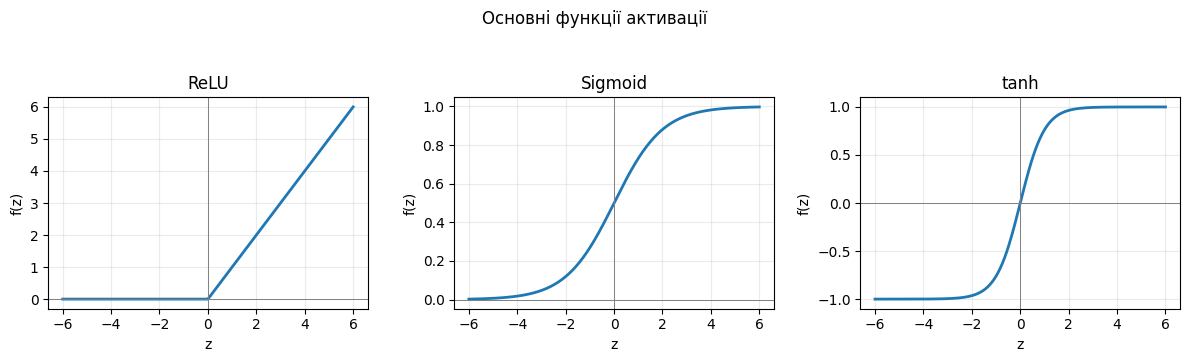

In [26]:
z_values = np.linspace(-6, 6, 400)
activation_functions = {
    "ReLU": np.maximum(0, z_values),
    "Sigmoid": 1 / (1 + np.exp(-z_values)),
    "tanh": np.tanh(z_values),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (name, values) in zip(axes, activation_functions.items()):
    ax.plot(z_values, values, linewidth=2)
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.axvline(0, color="gray", linewidth=0.7)
    ax.set_title(name)
    ax.set_xlabel("z")
    ax.set_ylabel("f(z)")
    ax.grid(alpha=0.25)
plt.suptitle("Основні функції активації", y=1.05)
plt.tight_layout()
plt.show()

###**Пояснення:**

Спочатку за допомогою `np.linspace(-6, 6, 400)` створюється масив із 400 рівномірно розподілених значень у діапазоні від -6 до 6, які використовуються для дослідження функцій активації.

Далі у словнику `activation_functions` задаються три основні функції активації нейронних мереж:

- `ReLU` – повертає нуль для від’ємних значень аргументу та саме значення аргументу для додатних.

- `Sigmoid` – перетворює вхідні значення у діапазон від 0 до 1, що дозволяє інтерпретувати результат як імовірність.

- `tanh` – перетворює вхідні значення у діапазон від -1 до 1, зберігаючи від’ємні та додатні значення.

За допомогою `plt.subplots(1, 3, figsize=(12, 3.4))` створюється область із трьома графіками, на яких у циклі `for` відображаються відповідні функції активації. Для кожного графіка задаються назва, підписи осей, координатні лінії та сітка.

Аналіз отриманих графіків показує, що функція `ReLU` дорівнює нулю для від’ємних значень та лінійно зростає для додатних. Функція `Sigmoid` має `S`-подібну форму, наближається до 0 при великих від’ємних значеннях і до 1 при великих додатних значеннях, а при `z = 0` дорівнює 0,5. Функція `tanh` також має `S`-подібну форму, проте є симетричною відносно початку координат, наближається до -1 та 1 і при `z = 0` дорівнює 0.

## 3. Набір даних для класифікації

Працюватимемо з **`digits`** із `scikit-learn`: 1797 зображень рукописних цифр розміром **8 × 8** пікселів. Класи позначено числами **0–9**. Значення яскравості пікселів спочатку лежать у діапазоні 0–16.

Кожному зображенню відповідає правильна мітка $y$. Перш ніж будувати модель, важливо перевірити структуру даних і побачити кілька прикладів.

Форма масиву зображень: (1797, 8, 8)
Форма масиву міток: (1797,)
Класи: [0 1 2 3 4 5 6 7 8 9]
Діапазон пікселів: 0.0 — 16.0


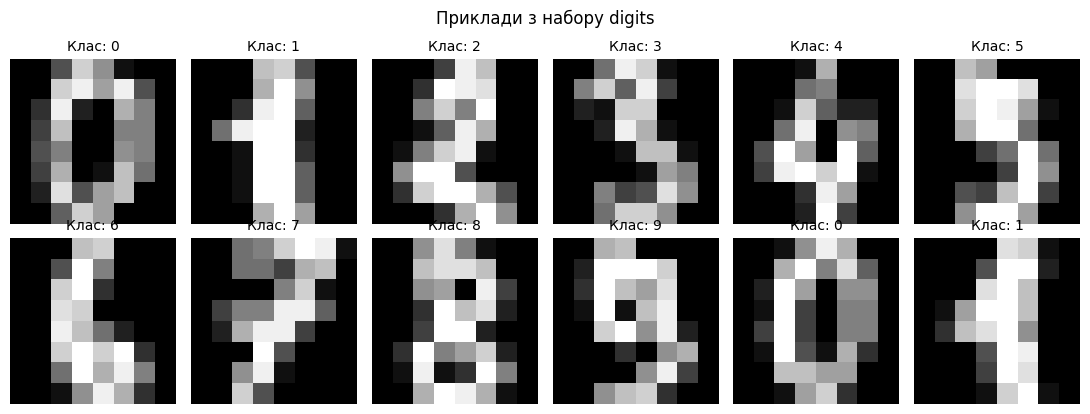

In [27]:
digits = load_digits()
images = digits.images
labels = digits.target

print("Форма масиву зображень:", images.shape)
print("Форма масиву міток:", labels.shape)
print("Класи:", np.unique(labels))
print("Діапазон пікселів:", images.min(), "—", images.max())

fig, axes = plt.subplots(2, 6, figsize=(11, 4.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray", vmin=0, vmax=16)
    ax.set_title(f"Клас: {labels[i]}", fontsize=10)
    ax.axis("off")
plt.suptitle("Приклади з набору digits")
plt.tight_layout()
plt.show()

###**Пояснення:**

Спочатку за допомогою функції `load_digits()` із бібліотеки `scikit-learn` завантажується набір даних `digits`, який містить зображення рукописних цифр від 0 до 9. Змінна `images = digits.images` використовується для збереження масиву зображень, а `labels = digits.target` – для збереження відповідних міток класів.

Далі за допомогою атрибута `shape` визначаються розміри масивів зображень і міток. Функція `np.unique(labels)` дозволяє отримати перелік унікальних класів, а методи `images.min()` та `images.max()` – визначити мінімальне й максимальне значення яскравості пікселів.

Для візуалізації даних за допомогою `plt.subplots(2, 6, figsize=(11, 4.2))` створюється область із 12 графіками, розташованими у два рядки по шість зображень. У циклі `for` за допомогою методу `imshow()` відображаються перші 12 зображень рукописних цифр у відтінках сірого (`cmap="gray"`). Для кожного зображення вказується його правильний клас, а координатні осі приховуються за допомогою `ax.axis("off")`.

У результаті виконання комірки отримано інформацію про структуру набору даних:

- Форма масиву зображень: (1797, 8, 8) – набір містить 1797 зображень розміром 8 × 8 пікселів.

- Форма масиву міток: (1797,) – кожному зображенню відповідає одна мітка класу.

- Класи: [0 1 2 3 4 5 6 7 8 9] – у наборі представлено 10 класів рукописних цифр.

- Діапазон значень пікселів: від 0.0 до 16.0, де 0 відповідає найтемнішому значенню, а 16 – найсвітлішому.

### Підготовка та поділ даних

Поділимо зображення на **навчальну**, **валідаційну** та **тестову** вибірки. Навчальна вибірка потрібна для оновлення ваг, валідаційна — для спостереження за якістю під час навчання, тестова — для завершальної незалежної оцінки. Параметр `stratify` допомагає зберегти співвідношення класів.

Пікселі нормалізуємо за формулою $x_{norm}=x/16$, тобто приведемо до діапазону $[0,1]$.

In [28]:
x_all = images.astype("float32") / 16.0
y_all = labels.astype("int64")

# 80% даних — для навчання + валідації; 20% — тест
x_trainval, x_test, y_trainval, y_test = train_test_split(
    x_all, y_all, test_size=0.20, random_state=42, stratify=y_all
)

# Із trainval виділяємо 20% для валідації
x_train, x_val, y_train, y_val = train_test_split(
    x_trainval, y_trainval, test_size=0.20,
    random_state=42, stratify=y_trainval
)

for name, x_part, y_part in [
    ("Навчальна", x_train, y_train),
    ("Валідаційна", x_val, y_val),
    ("Тестова", x_test, y_test),
]:
    print(f"{name:12s}: x={x_part.shape}, y={y_part.shape}")

assert np.all((x_train >= 0) & (x_train <= 1))
assert x_train.shape[1:] == (8, 8)
assert len(np.unique(y_train)) == 10

Навчальна   : x=(1149, 8, 8), y=(1149,)
Валідаційна : x=(288, 8, 8), y=(288,)
Тестова     : x=(360, 8, 8), y=(360,)


###**Пояснення:**

Спочатку виконується нормалізація значень яскравості пікселів за допомогою операції `images.astype("float32") / 16.0`. При цьому значення пікселів перетворюються на тип `float32` та діляться на 16, завдяки чому початковий діапазон [0; 16] приводиться до [0; 1]. Мітки класів за допомогою `labels.astype("int64")` перетворюються на цілочисельний тип `int64`.

Далі за допомогою функції `train_test_split()` виконується поділ набору даних на навчальну, валідаційну та тестову вибірки у два етапи.

На першому етапі 80% даних виділяється для подальшого формування навчальної та валідаційної вибірок, а 20% – для тестування моделі. На другому етапі з отриманих 80% даних виділяється ще 20% для валідації, а решта використовується для навчання. Таким чином, загальний розподіл становить приблизно 64% для навчання, 16% для валідації та 20% для тестування.

Параметр `random_state=42` забезпечує відтворюваність результатів поділу, а `stratify` дозволяє зберегти приблизно однакові пропорції класів у сформованих вибірках.

Після поділу за допомогою циклу `for` та атрибута `shape` виводяться розміри масивів зображень і відповідних міток для кожної вибірки.

Додатково команди `assert` перевіряють правильність підготовки даних: належність нормалізованих значень навчальної вибірки до діапазону [0; 1], відповідність розміру зображень 8 × 8 пікселів та наявність усіх 10 класів у навчальній вибірці.

У результаті виконання комірки отримано такі розміри вибірок:

- Навчальна вибірка: `x=(1149, 8, 8), y=(1149,)` – містить 1149 зображень для навчання нейронної мережі.

- Валідаційна вибірка: `x=(288, 8, 8), y=(288,)` – містить 288 зображень для контролю якості моделі під час навчання.

- Тестова вибірка: `x=(360, 8, 8), y=(360,)` – містить 360 зображень для незалежного оцінювання навченої моделі.

## 4. Архітектура повнозв’язної нейронної мережі

**Повнозв’язний шар (`Dense`)** означає, що кожний його нейрон отримує виходи всіх нейронів попереднього шару. Для матриці входів $X$ та ваг $W$ виконується перетворення

$$
H=f(XW+b).
$$

Ми використаємо такі шари:

- `Flatten` — перетворює зображення $8\times 8$ на вектор із 64 ознак (без навчуваних параметрів).
- `Dense(64)` — перший повнозв’язний шар.
- `BatchNormalization` — нормалізує проміжні активації; зберігає навчувані коефіцієнти масштабу та зміщення.
- `Activation("relu")` — задає нелінійність.
- `Dropout(0.2)` — під час навчання випадково зануляє приблизно 20% активацій для регуляризації.
- `Dense(32)` — другий повнозв’язний шар.
- `Dense(10, activation="softmax")` — повертає десять оцінок належності до класів.

Під час **передбачення** (`predict`) `Dropout` не вимикає нейрони випадковим чином; `BatchNormalization` використовує накопичені статистики.

In [29]:
model = keras.Sequential([
    keras.Input(shape=(8, 8), name="image"),
    layers.Flatten(name="flatten"),
    layers.Dense(64, use_bias=False, name="dense_64"),
    layers.BatchNormalization(name="batch_norm"),
    layers.Activation("relu", name="relu"),
    layers.Dropout(0.20, name="dropout"),
    layers.Dense(32, activation="relu", name="dense_32"),
    layers.Dense(10, activation="softmax", name="classes"),
], name="digits_mlp")

model.summary()
print("Всього параметрів:", model.count_params())

Model: "digits_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm (BatchNormalization) │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu (Activation)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classes (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,762 (26.41 KB)

 Trainable params: 6,634 (25.91 KB)

 Non-trainable params: 128 (512.00 B)

Всього параметрів: 6762


###**Пояснення:**

Спочатку за допомогою `keras.Sequential()` створюється послідовна модель повнозв’язної нейронної мережі `MLP (Multilayer Perceptron)` для класифікації рукописних цифр із набору даних `digits`.

Архітектура моделі складається з таких шарів:

- `keras.Input(shape=(8, 8))` – визначає форму вхідних даних, якими є зображення рукописних цифр розміром 8 × 8 пікселів.

- `Flatten` – перетворює двовимірне зображення розміром 8 × 8 на одновимірний вектор із 64 ознак без зміни їхніх значень.

- `Dense(64, use_bias=False)` – перший повнозв’язний шар, що містить 64 нейрони та виконує лінійне перетворення вхідних ознак. Параметр `use_bias=False` вимикає використання зсуву, оскільки наступним застосовується шар нормалізації.

- `BatchNormalization` – нормалізує проміжні значення, що сприяє стабілізації процесу навчання нейронної мережі.

- `Activation("relu")` – застосовує функцію активації `ReLU`, яка додає нелінійність і дозволяє моделі виявляти складніші закономірності в даних.

- `Dropout(0.20)` – під час навчання випадковим чином занулює 20% виходів нейронів, що допомагає зменшити ризик перенавчання.

- `Dense(32, activation="relu")` – другий повнозв’язний шар із 32 нейронами та функцією активації `ReLU`, який забезпечує подальше опрацювання отриманих ознак.

- `Dense(10, activation="softmax")` – вихідний шар із 10 нейронами, кожен із яких відповідає одному класу цифр від 0 до 9. Функція `softmax` перетворює вихідні значення на розподіл імовірностей належності зображення до відповідних класів.

Після створення моделі за допомогою методу `model.summary()` виводиться інформація про її архітектуру, розміри вихідних даних кожного шару та кількість параметрів. Метод `model.count_params()` використовується для визначення загальної кількості параметрів нейронної мережі.

Найбільшу кількість параметрів має перший повнозв’язний шар `Dense(64)` – 4096, оскільки кожна з 64 вхідних ознак з’єднується з кожним із 64 нейронів. Другий повнозв’язний шар містить 2080 параметрів, а вихідний шар – 330 параметрів. Шар `BatchNormalization` містить 256 параметрів, із яких 128 є навчальними та 128 – ненавчальними.

### Як читати `model.summary()`

Таблиця `summary()` показує **назву шару**, **форму виходу** та **кількість параметрів**. Для `Dense` кількість параметрів дорівнює $n_{in}\cdot n_{out}+n_{out}$, якщо використовується зсув `bias`; без нього — $n_{in}\cdot n_{out}$.

У нашій моделі перший `Dense` без зсуву має $64\cdot64=4096$ параметрів; наступний `Dense(32)` має $64\cdot32+32=2080$, а вихідний — $32\cdot10+10=330$. `BatchNormalization` додає власні параметри та статистики.

Схему мережі можна зберегти через `keras.utils.plot_model()`. Наступна комірка **необов’язкова**: якщо Graphviz або `pydot` не встановлено, навчання все одно працюватиме.

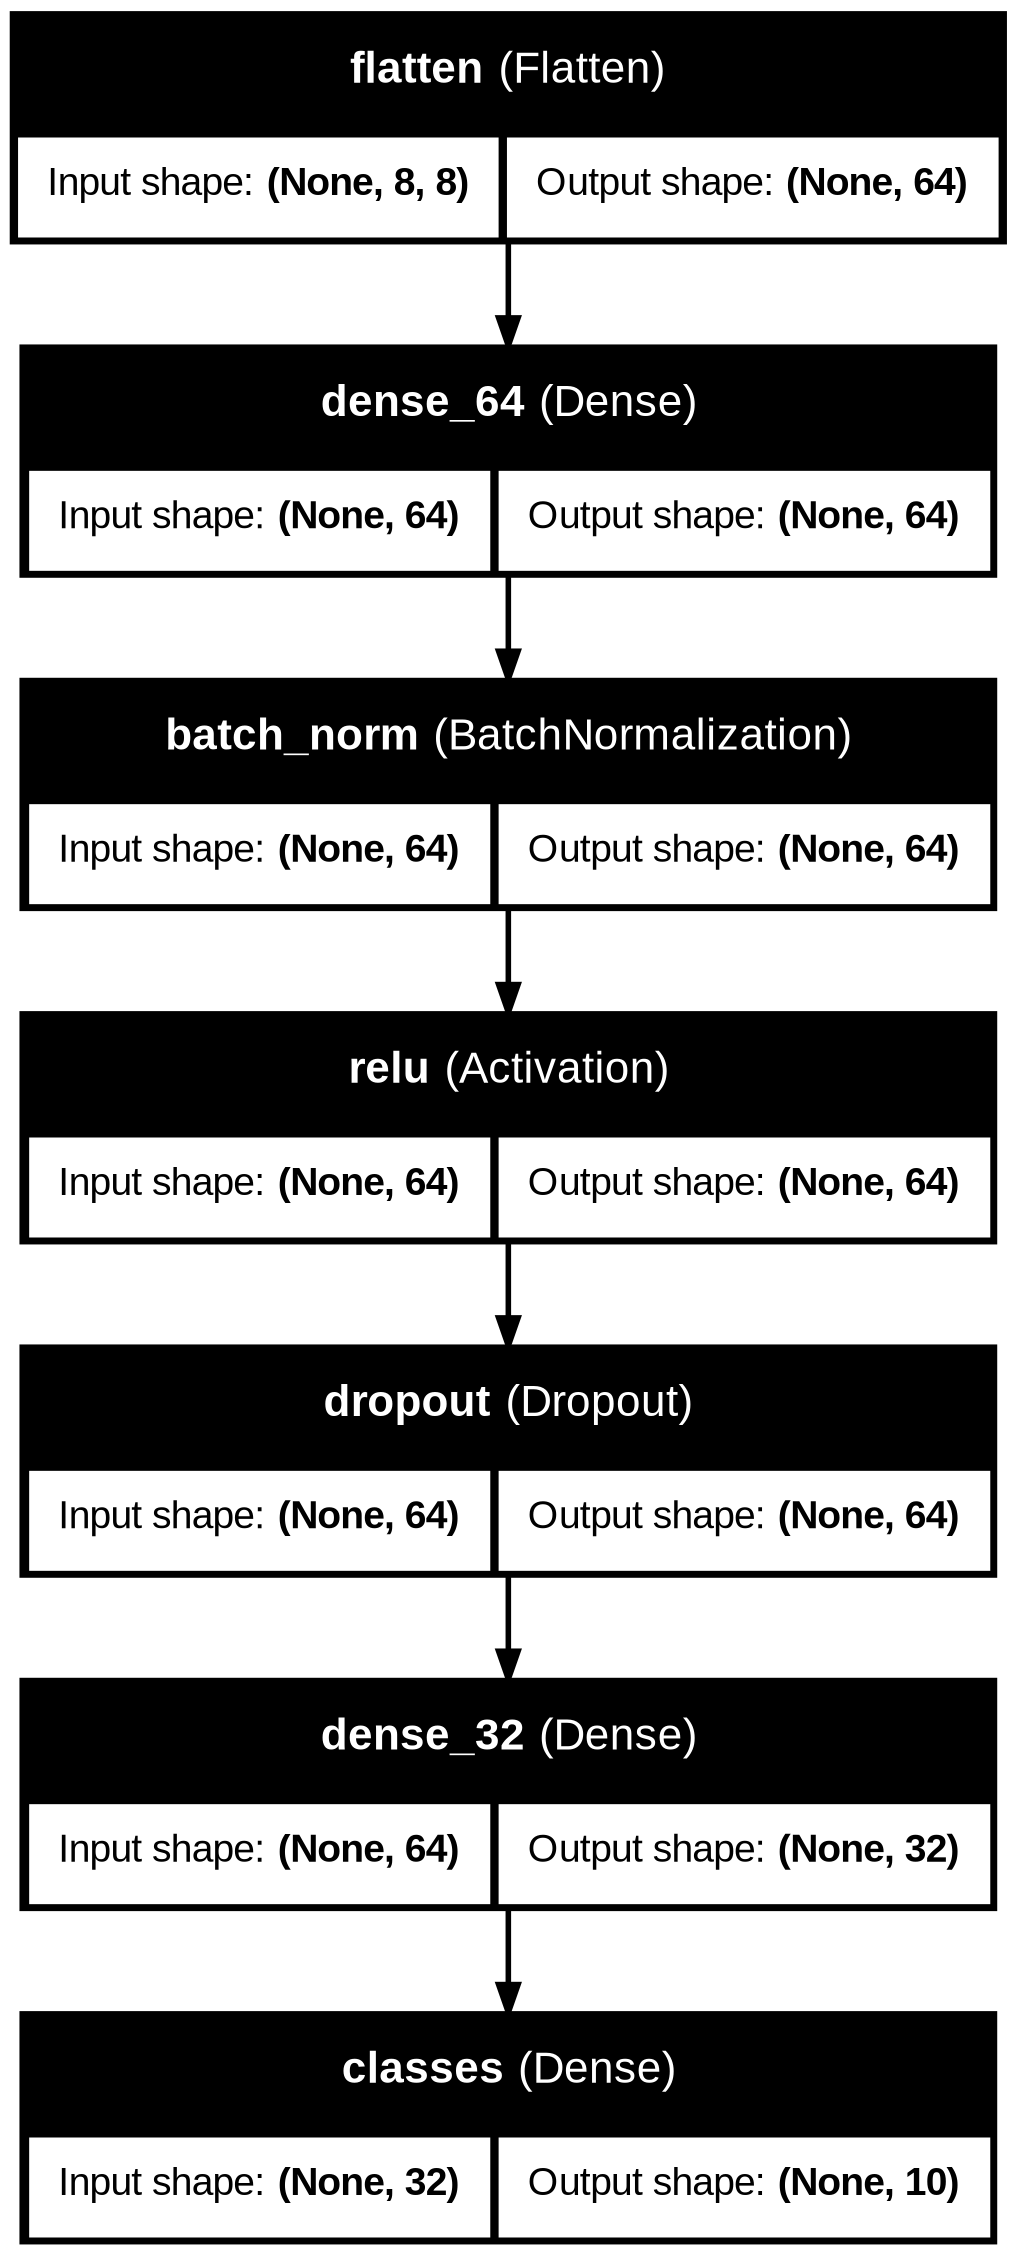

In [30]:
try:
    from IPython.display import Image, display

    keras.utils.plot_model(
        model,
        to_file="digits_mlp_architecture.png",
        show_shapes=True,
        show_layer_names=True,
        rankdir="TB",
    )
    display(Image(filename="digits_mlp_architecture.png"))
except Exception as exc:
    print("Графічна схема недоступна; скористайтеся model.summary().")
    print("Причина:", type(exc).__name__, str(exc)[:250])

###**Пояснення:**

Спочатку за допомогою конструкції `try...except` реалізується побудова графічної схеми архітектури створеної нейронної мережі з можливістю обробки помилок у разі відсутності необхідних бібліотек.

Із модуля `IPython.display` імпортуються `Image` та `display`, які використовуються для завантаження й відображення зображення безпосередньо в середовищі Google Colab.

Далі за допомогою функції `keras.utils.plot_model()` створюється графічне представлення моделі `digits_mlp`. Параметр `to_file="digits_mlp_architecture.png"` задає назву файлу для збереження схеми, `show_shapes=True` забезпечує відображення розмірів вхідних і вихідних даних кожного шару, `show_layer_names=True` – назв шарів, а `rankdir="TB"` визначає вертикальне розташування елементів схеми зверху вниз.

Після створення графічного файлу команда `display(Image(filename="digits_mlp_architecture.png"))` виводить отриману схему на екран. У разі виникнення помилки блок `except` виводить повідомлення про недоступність графічної схеми та причину помилки.

Аналіз отриманої схеми показує, що спочатку шар `Flatten` перетворює вхідне зображення розміром 8 × 8 пікселів на вектор із 64 ознак. Далі шар `Dense(64)` виконує перетворення цих ознак, зберігаючи розмірність вихідного вектора `(None, 64)`.

Шари `BatchNormalization`, `Activation (ReLU)` та `Dropout` виконують нормалізацію, нелінійне перетворення й регуляризацію проміжних значень без зміни їхньої розмірності. Після цього шар `Dense(32)` зменшує кількість ознак із 64 до 32, а вихідний шар `Dense(10)` формує вектор із 10 значень, що відповідають імовірностям належності зображення до кожного класу рукописних цифр.

Позначення `None` у формах вхідних і вихідних даних означає змінний розмір пакета зображень, який може використовуватися під час навчання та прогнозування.

## 5. Функція втрат, оптимізатори та компіляція

Під час навчання мережа прогнозує клас, а **функція втрат** оцінює невідповідність між прогнозом і правильною міткою. Градієнти обчислюються автоматично за алгоритмом **зворотного поширення помилки** (backpropagation). Оптимізатор оновлює ваги у напрямі зменшення втрат.

Для звичайного градієнтного спуску крок оновлення має вигляд:

$$
w_{t+1}=w_t-\eta\nabla_w L(w_t),
$$

де $\eta$ — швидкість навчання (*learning rate*).

**SGD** виконує градієнтні оновлення, **Adam** адаптує масштаб кроків для різних параметрів, а **AdamW** додатково реалізує відокремлене зменшення ваг (*weight decay*). Тут візьмемо `Adam(learning_rate=0.001)`.

Для **10 класів із цілочисельними мітками** підходить `SparseCategoricalCrossentropy`. Метрика `accuracy` — частка правильних відповідей.

In [31]:
# Приклади альтернатив (для ознайомлення):
sgd_optimizer = keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
adam_optimizer = keras.optimizers.Adam(learning_rate=0.001)

model.compile(
    optimizer=adam_optimizer,
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

print("Оптимізатор моделі:", type(model.optimizer).__name__)
print("Функція втрат: SparseCategoricalCrossentropy")

Оптимізатор моделі: Adam
Функція втрат: SparseCategoricalCrossentropy


###**Пояснення:**

Спочатку створюються два оптимізатори для навчання нейронної мережі: `SGD (Stochastic Gradient Descent)` та `Adam (Adaptive Moment Estimation)`.

Оптимізатор `keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)` реалізує стохастичний градієнтний спуск зі швидкістю навчання 0,01 та параметром інерції `momentum=0.9`, який дозволяє враховувати попередні оновлення ваг і сприяє стабільнішому процесу оптимізації.

Оптимізатор `keras.optimizers.Adam(learning_rate=0.001)` використовує адаптивне налаштування кроку оновлення для кожного параметра моделі. Значення `learning_rate=0.001` визначає початкову швидкість навчання.

Далі за допомогою методу `model.compile()` виконується налаштування нейронної мережі перед навчанням. При цьому задаються такі параметри:

- `optimizer=adam_optimizer` – вибирається оптимізатор `Adam` для оновлення ваг нейронної мережі.

- `loss=keras.losses.SparseCategoricalCrossentropy()` – задається функція втрат для задачі багатокласової класифікації, у якій правильні мітки класів представлені цілими числами від 0 до 9.

- `metrics=["accuracy"]` – визначається метрика точності класифікації, яка показує частку правильно класифікованих зображень серед усіх розглянутих прикладів.

Після компіляції за допомогою `type(model.optimizer).__name__` визначається назва оптимізатора, який використовується моделлю. Команди `print()` виводять інформацію про вибраний оптимізатор та функцію втрат.

## 6. Навчання моделі

Метод `fit()` здійснює багаторазове проходження навчальної вибірки. **Епоха** — один повний прохід, а **пакет (batch)** — частина прикладів, за якою виконується чергове оновлення ваг.

Після кожної епохи Keras обчислює `val_loss` і `val_accuracy`. **EarlyStopping** припиняє навчання, якщо валідаційні втрати не поліпшуються протягом кількох епох, і може повернути найкращі ваги.

In [32]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1,
)

print("Фактична кількість епох:", len(history.history["loss"]))

Epoch 1/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.3238 - loss: 2.0187 - val_accuracy: 0.4340 - val_loss: 1.9900
Epoch 2/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6675 - loss: 1.2706 - val_accuracy: 0.8229 - val_loss: 1.5783
Epoch 3/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8242 - loss: 0.8112 - val_accuracy: 0.9271 - val_loss: 1.1033
Epoch 4/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8764 - loss: 0.5418 - val_accuracy: 0.9444 - val_loss: 0.7300
Epoch 5/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9060 - loss: 0.3932 - val_accuracy: 0.9618 - val_loss: 0.4812
Epoch 6/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9286 - loss: 0.2999 - val_accuracy: 0.9653 - val_loss: 0.3308
Epoch 7/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9391 - loss: 0.2414 - val_accuracy: 0.9722 - val_loss: 0.2367
Epoch 8/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9530 - loss: 0.2011 - val_accuracy: 0.9688 - val_loss

###**Пояснення:**

Спочатку за допомогою `keras.callbacks.EarlyStopping()` створюється механізм ранньої зупинки навчання нейронної мережі, який дозволяє запобігти надмірному навчанню моделі та зменшити кількість зайвих епох.

При цьому задаються такі параметри:

- `monitor="val_loss"` – визначає валідаційну функцію втрат як основний показник для контролю якості навчання.

- `patience=5` – дозволяє продовжувати навчання протягом п’яти епох без покращення валідаційних втрат, після чого навчання автоматично припиняється.

- `restore_best_weights=True` – забезпечує відновлення ваг моделі, які відповідали найменшому значенню валідаційних втрат.

Далі за допомогою методу `model.fit()` виконується навчання нейронної мережі на навчальній вибірці `x_train` та відповідних мітках `y_train`. Параметр `validation_data=(x_val, y_val)` задає валідаційну вибірку для оцінювання якості моделі після кожної епохи. Значення `epochs=30` встановлює максимальну кількість епох навчання, `batch_size=32` визначає розмір пакета з 32 зображень, а `callbacks=[early_stopping]` підключає механізм ранньої зупинки. Параметр `verbose=1` забезпечує відображення перебігу навчання.

Результати навчання зберігаються у змінній `history`, яка містить значення функції втрат і точності класифікації для навчальної та валідаційної вибірок на кожній епосі. За допомогою `len(history.history["loss"])` визначається фактична кількість виконаних епох.

Аналіз отриманих результатів показує, що протягом навчання відбулося суттєве покращення якості класифікації:

- Точність на навчальній вибірці (`accuracy`) зросла з 0.3238 (32,38%) на першій епосі до 0.9904 (99,04%) на 24-й епосі.

- Втрати на навчальній вибірці (`loss`) зменшилися з 2.0187 до 0.0408, що свідчить про поступове зменшення помилок моделі.

- Точність на валідаційній вибірці (`val_accuracy`) зросла з 0.4340 (43,40%) до 0.9757 (97,57%).

- Валідаційні втрати (`val_loss`) зменшилися з 1.9900 до мінімального значення 0.0662 на 19-й епосі, після чого почали коливатися та не демонстрували подальшого покращення.

Завдяки параметру `restore_best_weights=True` після завершення навчання було відновлено ваги моделі, отримані на 19-й епосі, коли значення валідаційних втрат було найменшим.

## 7. Криві навчання: втрати та точність

Об’єкт `history` містить історію значень **`loss`**, **`val_loss`**, **`accuracy`**, **`val_accuracy`**. На графіку слід порівняти не лише кінцеві значення, а й динаміку:

- якщо обидві точності низькі — можливе **недонавчання**;
- якщо навчальна точність висока, а валідаційна значно нижча — можливе **перенавчання**;
- якщо валідаційна помилка стабілізується, а навчальна продовжує падати — доцільно перевірити регуляризацію й момент зупинки.

Через відмінності в режимах роботи Dropout/BatchNormalization валідаційні показники іноді можуть бути кращими за навчальні; сам по собі такий випадок не є помилкою.

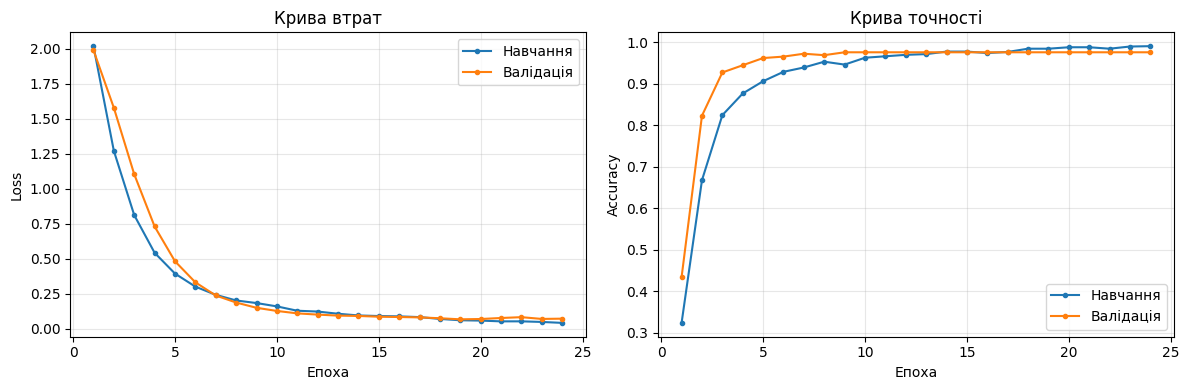

In [33]:
epochs_done = np.arange(1, len(history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_done, history.history["loss"], label="Навчання", marker="o", ms=3)
axes[0].plot(epochs_done, history.history["val_loss"], label="Валідація", marker="o", ms=3)
axes[0].set(title="Крива втрат", xlabel="Епоха", ylabel="Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_done, history.history["accuracy"], label="Навчання", marker="o", ms=3)
axes[1].plot(epochs_done, history.history["val_accuracy"], label="Валідація", marker="o", ms=3)
axes[1].set(title="Крива точності", xlabel="Епоха", ylabel="Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

###**Пояснення:**

Спочатку за допомогою `np.arange(1, len(history.history["loss"]) + 1)` створюється масив номерів епох відповідно до фактичної тривалості навчання нейронної мережі. У цьому випадку масив містить значення від 1 до 24, оскільки навчання було автоматично припинено механізмом `EarlyStopping`.

Далі за допомогою `plt.subplots(1, 2, figsize=(12, 4))` створюється область із двома графіками для візуалізації динаміки функції втрат і точності класифікації.

На першому графіку «Крива втрат» відображаються значення `loss` та `val_loss`, які характеризують зміну функції втрат на навчальній і валідаційній вибірках протягом кожної епохи.

На другому графіку «Крива точності» відображаються значення `accuracy` та `val_accuracy`, які дозволяють порівняти динаміку точності класифікації на навчальних і валідаційних даних.

Для побудови кривих використовується метод `plot()`, а за допомогою `set()`, `legend()` та `grid()` задаються назви графіків, підписи осей, легенди та координатні сітки.

Аналіз графіка «Крива втрат» показує, що на початкових епохах значення функції втрат стрімко зменшуються як на навчальній, так і на валідаційній вибірках. Зокрема, навчальні втрати знизилися з 2.0187 до 0.0408, а валідаційні – з 1.9900 до мінімального значення 0.0662 на 19-й епосі. Після цього навчальні втрати продовжували зменшуватися, тоді як валідаційні почали незначно коливатися, що може свідчити про появу початкових ознак перенавчання.

Аналіз графіка «Крива точності» показує поступове підвищення точності класифікації протягом навчання. На першій епосі точність навчальної вибірки становила 32,38%, а валідаційної – 43,40%. Уже після перших кількох епох спостерігається суттєве зростання цих показників. Наприкінці навчання точність на навчальній вибірці досягла 99,04%, а на валідаційній – 97,57%.

Починаючи приблизно з 9–10-ї епохи, валідаційна точність стабілізується на рівні близько 97–98%, тоді як навчальна точність продовжує поступово зростати. Водночас різниця між показниками залишається відносно невеликою, що свідчить про достатню здатність моделі узагальнювати дані, які не використовувалися безпосередньо для оновлення ваг.

На початкових епохах валідаційна точність перевищує навчальну. Це може пояснюватися використанням шарів `Dropout` та `BatchNormalization`, які працюють у різних режимах під час навчання та валідації.

## 8. Оцінювання та візуалізація класифікації

Після навчання один раз оцінюємо модель на **тестовій вибірці**, яка не використовувалася ні для навчання, ні для підбору параметрів. Метод `evaluate()` поверне втрати й точність, а `predict()` — вектор із 10 значень softmax для кожного зображення.

Щоб отримати номер прогнозованого класу, застосуємо `np.argmax(..., axis=1)`. Далі покажемо зображення з підписами **«Справжній клас»** і **«Прогноз»**. Зеленим виділимо правильні відповіді, червоним — помилки.

In [34]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
probabilities = model.predict(x_test, verbose=0)
predicted_classes = np.argmax(probabilities, axis=1)
confidence = probabilities.max(axis=1)

print(f"Тестові втрати: {test_loss:.4f}")
print(f"Тестова точність: {test_accuracy:.2%}")
print(f"Правильно: {(predicted_classes == y_test).sum()} із {len(y_test)}")
print("Форма прогнозів:", probabilities.shape)
assert probabilities.shape == (len(x_test), 10)

Тестові втрати: 0.0679
Тестова точність: 97.78%
Правильно: 352 із 360
Форма прогнозів: (360, 10)


###**Пояснення:**

Спочатку за допомогою методу `model.evaluate(x_test, y_test, verbose=0)` виконується оцінювання навченої нейронної мережі на тестовій вибірці, яка не використовувалася під час навчання та валідації. У результаті визначаються значення функції втрат `test_loss` та точності класифікації `test_accuracy`. Параметр `verbose=0` вимикає відображення проміжної інформації про процес оцінювання.

Далі за допомогою методу `model.predict(x_test, verbose=0)` формуються прогнози для всіх зображень тестової вибірки. Для кожного зображення модель повертає вектор із 10 значень, які відповідають імовірностям належності до класів рукописних цифр від 0 до 9.

За допомогою `np.argmax(probabilities, axis=1)` визначається прогнозований клас для кожного зображення шляхом вибору індексу найбільшої імовірності. Масив `confidence` містить максимальні значення цих імовірностей, що характеризують упевненість моделі у вибраному класі.

Після цього за допомогою функції `print()` виводяться тестові втрати, точність класифікації, кількість правильних прогнозів та форма масиву передбачень. Команда `assert probabilities.shape == (len(x_test), 10)` перевіряє відповідність розмірності отриманих прогнозів кількості тестових зображень і класів.

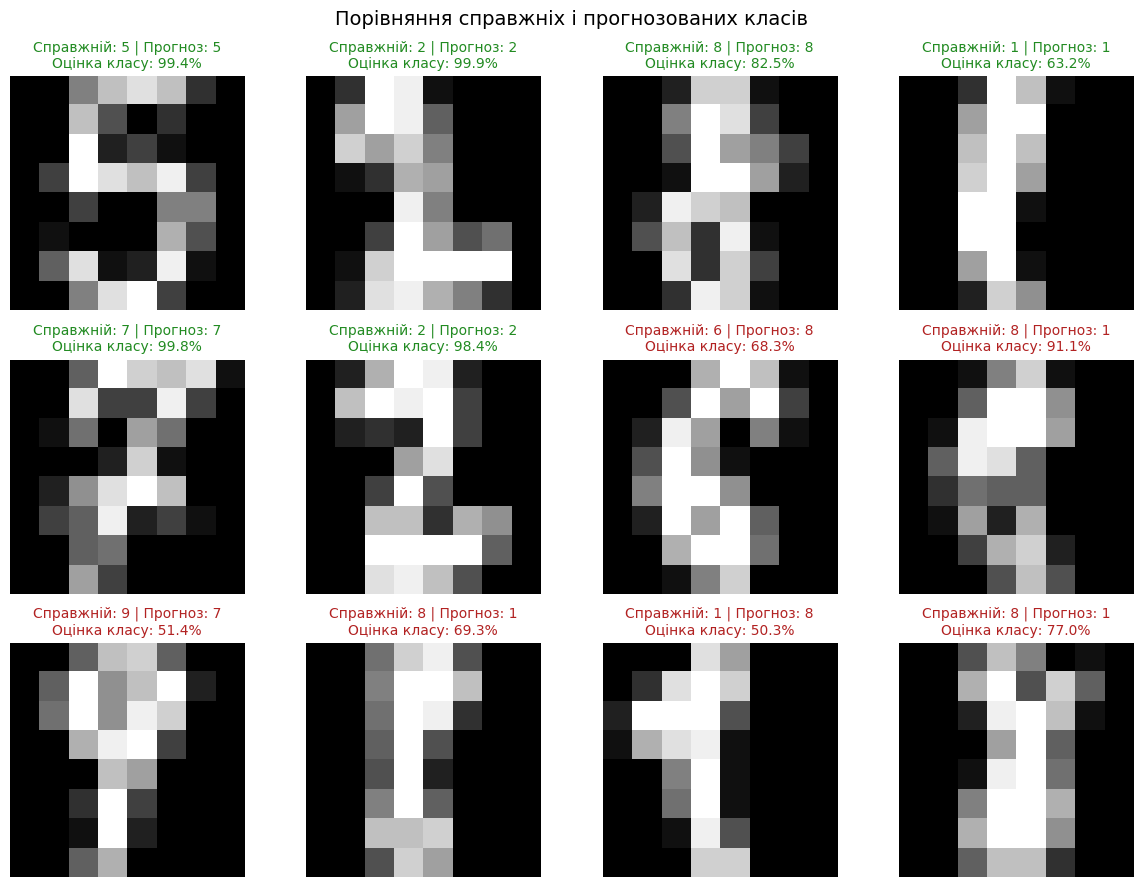

In [35]:
correct_idx = np.flatnonzero(predicted_classes == y_test)
wrong_idx = np.flatnonzero(predicted_classes != y_test)

# До 6 правильних і до 6 помилкових прикладів; решту місць доповнюємо правильними
selected = list(correct_idx[:6]) + list(wrong_idx[:6])
if len(selected) < 12:
    selected += list(correct_idx[6:6 + (12 - len(selected))])

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, idx in zip(axes.flat, selected):
    is_correct = predicted_classes[idx] == y_test[idx]
    color = "forestgreen" if is_correct else "firebrick"
    ax.imshow(x_test[idx], cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"Справжній: {y_test[idx]} | Прогноз: {predicted_classes[idx]}\n"
        f"Оцінка класу: {confidence[idx]:.1%}",
        color=color,
        fontsize=10,
    )
    ax.axis("off")
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor(color)
        spine.set_linewidth(2)
for ax in axes.flat[len(selected):]:
    ax.axis("off")
plt.suptitle("Порівняння справжніх і прогнозованих класів", fontsize=14)
plt.tight_layout()
plt.show()

###**Пояснення:**

Спочатку за допомогою `np.flatnonzero()` визначаються індекси зображень тестової вибірки, для яких нейронна мережа виконала правильні та помилкові прогнози. Масив `correct_idx` містить індекси правильно класифікованих зображень, а `wrong_idx` – індекси зображень, для яких прогнозований клас не збігається зі справжнім.

Далі формується список `selected`, до якого включаються перші шість правильних і перші шість помилкових прогнозів. Якщо кількість вибраних прикладів менша за 12, список доповнюється іншими правильно класифікованими зображеннями.

За допомогою `plt.subplots(3, 4, figsize=(12, 9))` створюється область із 12 графіками, розташованими у три рядки по чотири зображення.

У циклі `for` за допомогою методу `imshow()` відображаються вибрані зображення рукописних цифр у відтінках сірого. Для кожного зображення визначається правильність прогнозу та встановлюється відповідний колір підпису й рамки:

- Зелений (`forestgreen`) – правильний прогноз, коли передбачений клас збігається зі справжнім.

- Червоний (`firebrick`) – помилковий прогноз, коли передбачений клас відрізняється від справжнього.

Для кожного зображення за допомогою `set_title()` виводяться справжній клас, прогнозований клас та оцінка впевненості моделі у відсотках. Координатні осі приховуються за допомогою `ax.axis("off")`, а рамки зображень налаштовуються відповідно до правильності класифікації.

Аналіз отриманих результатів показує, що для правильно класифікованих цифр 5, 2, 8, 1, 7 та 2 модель визначила відповідні класи з оцінками впевненості від 63,2% до 99,9%. Найвищу впевненість серед наведених правильних прикладів отримано для цифри 1 – 99,9%.

Найбільша впевненість серед наведених помилкових прогнозів спостерігається для цифри 8, яку модель помилково визначила як 1 з імовірністю 91,1%. Це демонструє, що навіть висока впевненість нейронної мережі не завжди гарантує правильність класифікації.

Також помітно, що серед представлених помилок кілька разів зустрічається неправильне розпізнавання цифри 8 як 1. Це може бути пов’язано з особливостями написання рукописних цифр, низькою роздільною здатністю зображень та подібністю окремих графічних елементів.

### Матриця помилок і детальні метрики

**Матриця помилок** показує, які класи плутаються між собою. У рядках розташовано **справжні** класи, у стовпцях — **прогнозовані**. Крім accuracy, корисно переглядати **precision**, **recall** і **F1-score** для кожного класу.

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.921     0.972     0.946        36
           2      0.946     1.000     0.972        35
           3      1.000     1.000     1.000        37
           4      1.000     1.000     1.000        36
           5      1.000     1.000     1.000        37
           6      1.000     0.972     0.986        36
           7      0.973     1.000     0.986        36
           8      0.938     0.857     0.896        35
           9      1.000     0.972     0.986        36

    accuracy                          0.978       360
   macro avg      0.978     0.977     0.977       360
weighted avg      0.978     0.978     0.978       360



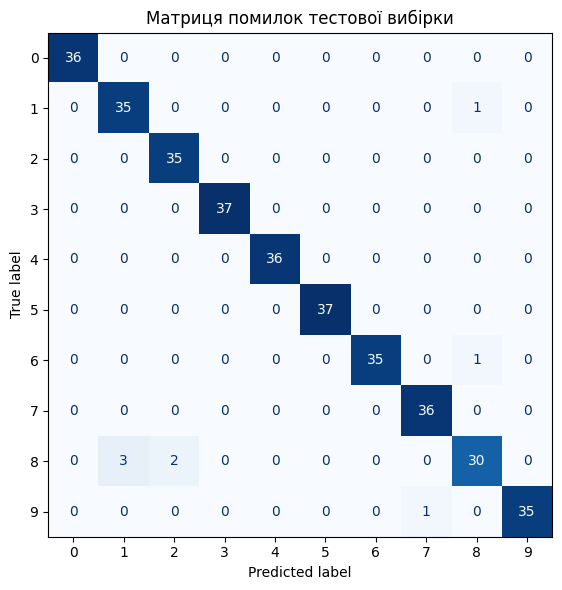

In [36]:
print(classification_report(y_test, predicted_classes, digits=3, zero_division=0))

matrix = confusion_matrix(y_test, predicted_classes, labels=np.arange(10))
display_matrix = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=np.arange(10))
fig, ax = plt.subplots(figsize=(7, 6))
display_matrix.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Матриця помилок тестової вибірки")
plt.tight_layout()
plt.show()

###**Пояснення:**

Спочатку за допомогою функції `classification_report(y_test, predicted_classes, digits=3, zero_division=0)` формується детальний звіт про якість класифікації нейронної мережі на тестовій вибірці. Для кожного з десяти класів рукописних цифр обчислюються такі показники:

- `Precision` (точність передбачень) – частка правильних прогнозів серед усіх зображень, які модель віднесла до певного класу.

- `Recall` (повнота) – частка правильно розпізнаних зображень серед усіх зображень, що насправді належать до відповідного класу.

- `F1-score` – гармонійне середнє значень `precision` та `recall`, яке дозволяє комплексно оцінити якість класифікації.

- `Support` – кількість зображень кожного класу в тестовій вибірці.
Параметр `digits=3` забезпечує відображення метрик із точністю до трьох знаків після коми, а `zero_division=0` визначає нульове значення метрики у випадках, коли її неможливо обчислити через ділення на нуль.

Далі за допомогою функції `confusion_matrix(y_test, predicted_classes, labels=np.arange(10))` створюється матриця помилок для десяти класів рукописних цифр. Рядки матриці відповідають справжнім класам, а стовпці – прогнозованим. Значення на головній діагоналі відображають кількість правильних прогнозів, тоді як значення поза діагоналлю показують помилкові класифікації.

Для графічного представлення матриці використовується `ConfusionMatrixDisplay()`, а метод `plot()` забезпечує її відображення у вигляді теплової карти з колірною схемою `Blues`. Параметр `values_format="d"` дозволяє відображати кількість зображень цілими числами, а `colorbar=False` вимикає додаткову колірну шкалу.

Аналіз отриманих метрик показує, що нейронна мережа досягла високої якості класифікації:

- `Accuracy`: 0.978 (97,78%) – модель правильно класифікувала 352 із 360 зображень.

- `Macro avg Precision`: 0.978 – середня точність передбачень за всіма класами.

- `Macro avg Recall`: 0.977 – середня повнота за всіма класами.

- `Macro avg F1-score`: 0.977 – середнє значення `F1-score` без урахування кількості зображень кожного класу.

- `Weighted avg F1-score`: 0.978 – середнє значення `F1-score` з урахуванням кількості зображень у кожному класі.

Найкращі результати отримано для класів 0, 3, 4 та 5, для яких усі три метрики `precision`, `recall` та `f1-score` дорівнюють 1.000. Це означає, що всі зображення цих класів були правильно розпізнані, а помилкових віднесень інших цифр до цих класів не було.

Найнижче значення `F1-score` спостерігається для класу 8 – 0.896, що свідчить про більшу складність розпізнавання цієї цифри порівняно з іншими класами. Для класу 1 значення `F1-score` становить 0.946, а для класу 2 – 0.972.

Аналіз побудованої матриці помилок показує, що більшість значень зосереджена на головній діагоналі, що підтверджує високу точність класифікації. Водночас виявлено 8 помилкових прогнозів:

- Одне зображення цифри 1 помилково класифіковано як 8.
- Одне зображення цифри 6 помилково класифіковано як 8.
- Три зображення цифри 8 помилково класифіковано як 1.
- Два зображення цифри 8 помилково класифіковано як 2.
- Одне зображення цифри 9 помилково класифіковано як 7.

Найбільше помилок пов’язано з цифрою 8, оскільки з 35 її зображень правильно розпізнано 30, а 5 віднесено до інших класів. Це пояснює найнижче значення повноти `recall = 0.857` серед усіх класів. Такі помилки можуть бути пов’язані з особливостями написання рукописних цифр, подібністю їхніх контурів та низькою роздільною здатністю зображень.

## 9. Збереження та відновлення навченої моделі

Формат **`.keras`** дає змогу зберегти архітектуру, параметри та стан моделі. Після завантаження перевіримо, що результати прогнозування збігаються з результатами вихідної моделі. Передоброблення нових даних має бути таким самим, як під час навчання (у нашому випадку — ділення пікселів на 16).

In [37]:
model.save("digits_mlp.keras")
restored_model = keras.models.load_model("digits_mlp.keras")

original_predictions = model.predict(x_test[:5], verbose=0)
restored_predictions = restored_model.predict(x_test[:5], verbose=0)
np.testing.assert_allclose(original_predictions, restored_predictions, atol=1e-6, rtol=1e-5)

print("Модель збережено до digits_mlp.keras і успішно відновлено.")

Модель збережено до digits_mlp.keras і успішно відновлено.


###**Пояснення:**

Спочатку за допомогою методу `model.save("digits_mlp.keras")` виконується збереження навченої нейронної мережі у файл формату `.keras`. Цей формат дозволяє зберегти архітектуру моделі, значення навчених ваг, налаштування компіляції та стан оптимізатора, що забезпечує можливість її подальшого використання без повторного навчання.

Далі за допомогою `keras.models.load_model("digits_mlp.keras")` збережена модель завантажується з файлу та присвоюється змінній `restored_model`.

Для перевірки правильності відновлення за допомогою методу `predict()` виконуються прогнози для перших п’яти зображень тестової вибірки `x_test[:5]`. Результати вихідної моделі зберігаються у змінній `original_predictions`, а відновленої – у `restored_predictions`.

Після цього за допомогою `np.testing.assert_allclose()` здійснюється порівняння отриманих прогнозів з урахуванням допустимих числових похибок. Параметри `atol=1e-6` та `rtol=1e-5` визначають абсолютну й відносну допустимі похибки порівняння. Якщо результати не збігаються в межах заданої точності, виникає помилка перевірки.

Наприкінці за допомогою функції `print()` виводиться повідомлення про успішне збереження та відновлення моделі.

Перевірка прогнозів для перших п’яти зображень тестової вибірки показала, що результати вихідної та відновленої моделей збігаються в межах встановленої числової точності. Це підтверджує правильність збереження та завантаження параметрів нейронної мережі.

### Контрольні запитання до виконаних прикладів

1. Для чого шар `Flatten` потрібний перед `Dense` у нашій моделі?
2. Чому для десяти взаємовиключних класів використано `softmax`?
3. Чим відрізняється `loss` від `accuracy`, а `val_loss` — від `loss`?
4. Чому тестову вибірку не використовують для налаштування архітектури?
5. Що означає кількість параметрів у `model.summary()`?
6. Чому `Dropout` по-різному поводиться під час `fit()` та `predict()`?

Наведені вище приклади повністю виконувані. Наступне завдання необхідно реалізувати **самостійно**.

###**Відповіді на контрольні запитання до виконаних прикладів:**

**1) Для чого шар `Flatten` потрібний перед `Dense` у нашій моделі?**

Шар `Flatten` використовується для перетворення двовимірних зображень розміром 8 × 8 пікселів на одновимірний вектор із 64 ознак. Це необхідно, оскільки повнозв’язний шар `Dense` повинен отримувати вектор ознак, кожна з яких з’єднується з нейронами наступного шару. При цьому `Flatten` не змінює значення пікселів і не містить навчальних параметрів, а лише змінює форму представлення даних.

**2) Чому для десяти взаємовиключних класів використано `softmax`?**

Функція активації `softmax` використовується для багатокласової класифікації, коли кожне зображення належить лише до одного з десяти класів рукописних цифр від 0 до 9. Вона перетворює вихідні значення нейронів на ймовірності в діапазоні від 0 до 1, сума яких дорівнює 1. Це дозволяє визначити найбільш імовірний клас за допомогою `np.argmax()`, вибираючи нейрон із найбільшим вихідним значенням.

**3) Чим відрізняється `loss` від `accuracy`, а `val_loss` – від `loss`?**

`Loss` – це значення функції втрат, яке характеризує величину помилки прогнозування моделі. Чим менше його значення, тим краще прогнози відповідають правильним міткам класів з погляду вибраної функції втрат.

`Accuracy` – це метрика точності класифікації, яка показує частку правильно класифікованих зображень серед загальної кількості прикладів.

Основна відмінність між `loss` і `accuracy` полягає в тому, що функція втрат враховує значення прогнозованих імовірностей та використовується для оптимізації ваг, тоді як точність показує частку правильних відповідей.

`Val_loss` відрізняється від `loss` тим, що обчислюється на валідаційній вибірці, яка не використовується для оновлення ваг нейронної мережі. Натомість `loss` визначається на навчальній вибірці. Порівняння цих показників дозволяє контролювати процес навчання та виявляти можливе перенавчання моделі.

**4) Чому тестову вибірку не використовують для налаштування архітектури?**

Тестову вибірку не використовують для налаштування архітектури нейронної мережі, оскільки вона призначена для незалежного оцінювання якості вже навченої моделі. Якщо використовувати тестові дані для вибору кількості шарів, нейронів або інших гіперпараметрів, результати оцінювання можуть стати завищеними через пристосування моделі до особливостей тестової вибірки.

Для налаштування архітектури та контролю навчання використовується валідаційна вибірка. Тестова вибірка застосовується після завершення налаштування моделі, щоб об’єктивно оцінити її здатність класифікувати раніше невідомі дані.

**5) Що означає кількість параметрів у `model.summary()`?**

Кількість параметрів у `model.summary()` показує загальну кількість числових значень, які використовуються нейронною мережею, зокрема ваг, зсувів і параметрів нормалізації.

Для повнозв’язного шару `Dense` кількість параметрів визначається кількістю вхідних і вихідних нейронів. Якщо використовується зсув, вона обчислюється за формулою:

N = nіn * nout + nout

У створеній моделі `digits_mlp` загальна кількість параметрів становить 6762, із яких 6634 є навчальними, а 128 – ненавчальними. Навчальні параметри оновлюються під час оптимізації, тоді як ненавчальні параметри шару `BatchNormalization` зберігають статистичні характеристики проміжних значень.

Кількість параметрів характеризує складність моделі та впливає на її обчислювальні вимоги, здатність вивчати закономірності й ризик перенавчання.

**6) Чому `Dropout` по-різному поводиться під час `fit()` та `predict()`?**`

Шар `Dropout` використовується для регуляризації нейронної мережі та зменшення ризику перенавчання. Під час виконання `fit()` він випадковим чином занулює частину виходів нейронів, змушуючи модель не покладатися надмірно на окремі ознаки.

У створеній моделі використовується `Dropout(0.2)`, який під час навчання випадково занулює приблизно 20% активацій.

Під час виконання `predict()` шар `Dropout` вимикається, тому всі нейрони беруть участь у формуванні прогнозу. Це необхідно для отримання стабільних результатів класифікації без випадкового занулення значень. При цьому `Keras` автоматично масштабує активації під час навчання, щоб узгодити їх із режимом прогнозування.

Таким чином, під час `fit()` шар `Dropout` допомагає підвищити здатність моделі до узагальнення, а під час `predict()` забезпечує використання всіх навчених ознак для формування прогнозу.



---

# 10. Самостійне завдання — заповнити порожні комірки

**Завдання.** Створіть **нову повнозв’язну модель** для тих самих зображень `digits`, навчіть її та порівняйте з базовою моделлю `model`. Результат має містити **архітектуру**, **криві навчання**, **тестові метрики**, **зображення зі справжніми та прогнозованими класами** й **короткий висновок**.

**Вимоги до нового варіанта:**

- використайте `Flatten` і щонайменше два приховані шари `Dense`, наприклад **128 і 64 нейрони**;
- застосуйте `ReLU`, `BatchNormalization` та `Dropout` зі значенням `rate=0.30`;
- сформуйте вихід із **10 нейронів та softmax**;
- оберіть **SGD з momentum** або **AdamW**, поясніть свій вибір;
- навчайте до **25 епох**, використовуючи `EarlyStopping`;
- не змінюйте тестові мітки і не тренуйте модель на `x_test`.

**Орієнтовне оцінювання — 10 балів:** архітектура й `summary()` — 2; коректна компіляція та навчання — 2; криві — 2; оцінка та візуалізація прогнозів — 2; обґрунтований висновок — 2.

Нижче навмисно залишено **порожні комірки без розв’язків**. Заповніть їх власним кодом.

### Крок 1. Створіть нову модель

Використайте **нову змінну `student_model`** (не перезаписуйте базову `model`), додайте шари за умовою та виведіть її архітектуру через `summary()`.

In [38]:
student_model = keras.Sequential([
    keras.Input(shape = (8, 8), name = "image"),
    layers.Flatten(name = "flatten"),
    layers.Dense(128, use_bias = False, name = "dense_128"),
    layers.BatchNormalization(name = "batch_norm"),
    layers.Activation("relu", name = "relu"),
    layers.Dropout(0.30, name = "dropout"),
    layers.Dense(64, activation = "relu", name = "dense_64"),
    layers.Dense(10, activation = "softmax", name = "classes"),
], name = "student_digits_mlp")

student_model.summary()
print("Всього параметрів:", student_model.count_params())

Model: "student_digits_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm (BatchNormalization) │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu (Activation)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classes (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,610 (68.79 KB)

 Trainable params: 17,354 (67.79 KB)

 Non-trainable params: 256 (1.00 KB)

Всього параметрів: 17610


###**Пояснення:**

Спочатку за допомогою `keras.Sequential()` створюється нова послідовна модель повнозв’язної нейронної мережі `MLP (Multilayer Perceptron)` для класифікації рукописних цифр із набору даних `digits`. Модель зберігається в окремій змінній `student_model` під назвою `student_digits_mlp`, що дозволяє зберегти базову модель `model` для подальшого порівняння результатів.

Архітектура нової нейронної мережі складається з таких шарів:

- `keras.Input(shape=(8, 8))` – визначає форму вхідних зображень розміром 8 × 8 пікселів.

- `Flatten` – перетворює двовимірне зображення на одновимірний вектор із 64 ознак без зміни значень пікселів.

- `Dense(128, use_bias=False)` – перший повнозв’язний шар зі 128 нейронами, який виконує перетворення вхідних ознак. Параметр `use_bias=False` вимикає використання зсуву, оскільки наступним застосовується шар нормалізації.

- `BatchNormalization` – нормалізує проміжні значення, сприяючи стабілізації процесу навчання.

- `Activation("relu")` – застосовує функцію активації `ReLU`, яка додає нелінійність і дозволяє моделі виявляти складніші закономірності в даних.

- `Dropout(0.30)` – під час навчання випадковим чином занулює 30% активацій, що допомагає зменшити ризик перенавчання.

- `Dense(64, activation="relu")` – другий повнозв’язний шар із 64 нейронами, який забезпечує подальше опрацювання отриманих ознак.

- `Dense(10, activation="softmax")` – вихідний шар із 10 нейронами, кожен із яких відповідає одному класу рукописних цифр від 0 до 9. Функція `softmax` формує розподіл імовірностей належності зображення до відповідних класів.

Після створення нейронної мережі за допомогою методу `student_model.summary()` виводиться інформація про її архітектуру, розміри вихідних даних кожного шару та кількість параметрів. Метод `student_model.count_params()` використовується для визначення загальної кількості параметрів створеної моделі.

Найбільшу кількість параметрів має другий повнозв’язний шар `Dense(64)` – 8256, оскільки кожен із 128 нейронів попереднього шару з’єднується з кожним із 64 нейронів, а також використовуються 64 параметри зсуву. Перший повнозв’язний шар `Dense(128)` містить 8192 параметри, вихідний шар `Dense(10)` – 650 параметрів, а шар `BatchNormalization` – 512 параметрів, із яких 256 є навчальними та 256 – ненавчальними.

Порівняно з базовою моделлю `digits_mlp`, яка містила 6762 параметри та два приховані шари на 64 і 32 нейрони, нова модель має 17610 параметрів і два приховані шари на 128 і 64 нейрони. Крім того, значення `Dropout` збільшено з 0,20 до 0,30, що забезпечує сильнішу регуляризацію під час навчання.

### Крок 2. Скомпілюйте та навчіть модель

Оберіть оптимізатор `SGD(momentum=...)` **або** `AdamW`, налаштуйте `SparseCategoricalCrossentropy`, `accuracy`, `EarlyStopping` і збережіть історію в змінній **`student_history`**.

In [39]:
keras.utils.set_random_seed(42)
student_model_sgd = keras.models.clone_model(student_model)

keras.utils.set_random_seed(42)
student_model_adamw = keras.models.clone_model(student_model)

sgd_optimizer = keras.optimizers.SGD(
    learning_rate = 0.01,
    momentum = 0.9
)

adamw_optimizer = keras.optimizers.AdamW(
    learning_rate = 0.001,
    weight_decay = 0.0001
)

student_model_sgd.compile(
    optimizer = sgd_optimizer,
    loss = keras.losses.SparseCategoricalCrossentropy(),
    metrics = ["accuracy"]
)

student_model_adamw.compile(
    optimizer = adamw_optimizer,
    loss = keras.losses.SparseCategoricalCrossentropy(),
    metrics = ["accuracy"]
)

student_history_sgd = student_model_sgd.fit(
    x_train, y_train,
    validation_data = (x_val, y_val),
    epochs = 25,
    batch_size = 32,
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor = "val_loss",
            patience = 5,
            restore_best_weights = True
        )
    ],
    verbose = 1
)

student_history_adamw = student_model_adamw.fit(
    x_train, y_train,
    validation_data = (x_val, y_val),
    epochs = 25,
    batch_size = 32,
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor = "val_loss",
            patience = 5,
            restore_best_weights = True
        )
    ],
    verbose = 1
)

print("\nSGD:")
print("Кількість епох:", len(student_history_sgd.history["loss"]))
print("Найменші val_loss:", min(student_history_sgd.history["val_loss"]))
print("Найбільша val_accuracy:", max(student_history_sgd.history["val_accuracy"]))

print("\nAdamW:")
print("Кількість епох:", len(student_history_adamw.history["loss"]))
print("Найменші val_loss:", min(student_history_adamw.history["val_loss"]))
print("Найбільша val_accuracy:", max(student_history_adamw.history["val_accuracy"]))

Epoch 1/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5587 - loss: 1.3832 - val_accuracy: 0.8090 - val_loss: 1.3899
Epoch 2/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9008 - loss: 0.3822 - val_accuracy: 0.8854 - val_loss: 0.8176
Epoch 3/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9278 - loss: 0.2296 - val_accuracy: 0.9479 - val_loss: 0.5081
Epoch 4/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9469 - loss: 0.1683 - val_accuracy: 0.9688 - val_loss: 0.3284
Epoch 5/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9643 - loss: 0.1312 - val_accuracy: 0.9688 - val_loss: 0.2190
Epoch 6/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9748 - loss: 0.1132 - val_accuracy: 0.9757 - val_loss: 0.1575
Epoch 7/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9730 - loss: 0.0976 - val_accuracy: 0.9757 - val_loss: 0.1217
Epoch 8/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9843 - loss: 0.0790 - val_accuracy: 0.9722 - val_loss:

###**Пояснення:**

Спочатку за допомогою `keras.utils.set_random_seed(42)` встановлюється фіксоване початкове значення генераторів випадкових чисел для забезпечення відтворюваності результатів. Далі за допомогою `keras.models.clone_model(student_model)` створюються дві незалежні копії нової нейронної мережі з однаковою архітектурою та початковою ініціалізацією ваг. Перша модель `student_model_sgd` призначена для навчання з оптимізатором `SGD`, а друга `student_model_adamw` – з оптимізатором `AdamW`.

Після цього налаштовуються два оптимізатори:

- `SGD (Stochastic Gradient Descent)` – створюється за допомогою `keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)`. Швидкість навчання 0.01 визначає величину кроку оновлення ваг, а параметр `momentum=0.9` дозволяє враховувати попередні оновлення, сприяючи прискоренню та стабілізації процесу оптимізації.

- `AdamW (Adaptive Moment Estimation with Weight Decay)` – створюється за допомогою `keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.0001)`. Оптимізатор використовує адаптивне налаштування кроків оновлення ваг та додаткову регуляризацію `weight_decay`, яка сприяє зменшенню ризику перенавчання.
Далі за допомогою методу `compile()` виконується компіляція обох моделей. Для них використовується однакова функція втрат `SparseCategoricalCrossentropy`, призначена для багатокласової класифікації з цілочисельними мітками класів, та метрика `accuracy`, яка визначає частку правильних прогнозів.

Навчання моделей виконується за допомогою методу `fit()` на однакових навчальній і валідаційній вибірках. Максимальна кількість епох становить 25, розмір пакета `batch_size=32`, а механізм `EarlyStopping` контролює значення `val_loss` і припиняє навчання, якщо протягом п’яти епох не спостерігається покращення. Параметр `restore_best_weights=True` забезпечує відновлення ваг, які відповідали найменшим валідаційним втратам.

Історії навчання зберігаються в окремих змінних `student_history_sgd` та `student_history_adamw`, що дозволяє надалі порівнювати динаміку втрат і точності для обох оптимізаторів.

Наприкінці за допомогою `print()` виводяться фактична кількість виконаних епох, найменші значення валідаційних втрат `val_loss` та найбільші значення валідаційної точності `val_accuracy`.

Аналіз результатів навчання моделі з оптимізатором `SGD` показує, що вже на першій епосі точність навчальної вибірки становила 55,87%, а валідаційної – 80,90%. Протягом наступних епох спостерігалося поступове зростання точності та зменшення функції втрат. Найменше значення валідаційних втрат 0,0528 було досягнуто на 15-й епосі, після чого покращення цього показника не спостерігалося. Механізм `EarlyStopping` автоматично припинив навчання після 20-ї епохи та відновив найкращі ваги моделі. Максимальна валідаційна точність становила 97,92%.

Під час навчання моделі з оптимізатором `AdamW` на першій епосі точність навчальної вибірки становила 51,09%, а валідаційної – 82,29%. У процесі навчання значення функції втрат поступово зменшувалися, а точність класифікації зростала. Найменше значення валідаційних втрат 0,0471 було отримано на 22-й епосі, а максимальна валідаційна точність досягла 98,26%. Навчання тривало всі 25 запланованих епох, оскільки умова ранньої зупинки не була виконана.

Порівняння результатів показує, що оптимізатор `AdamW` забезпечив дещо кращі валідаційні показники, ніж `SGD`. Зокрема, максимальна валідаційна точність збільшилася з 97,92% до 98,26%, тобто приблизно на 0,34 відсотка, а найменше значення валідаційних втрат зменшилося з 0,0528 до 0,0471.

Водночас `SGD` потребував меншої кількості епох для досягнення свого найкращого результату, що свідчить про достатню ефективність цього оптимізатора для розглянутої задачі.

### Крок 3. Побудуйте криві навчання

Побудуйте два графіки: `loss` / `val_loss` і `accuracy` / `val_accuracy`. Порівняйте їхній перебіг та визначте, чи є ознаки перенавчання або недонавчання.

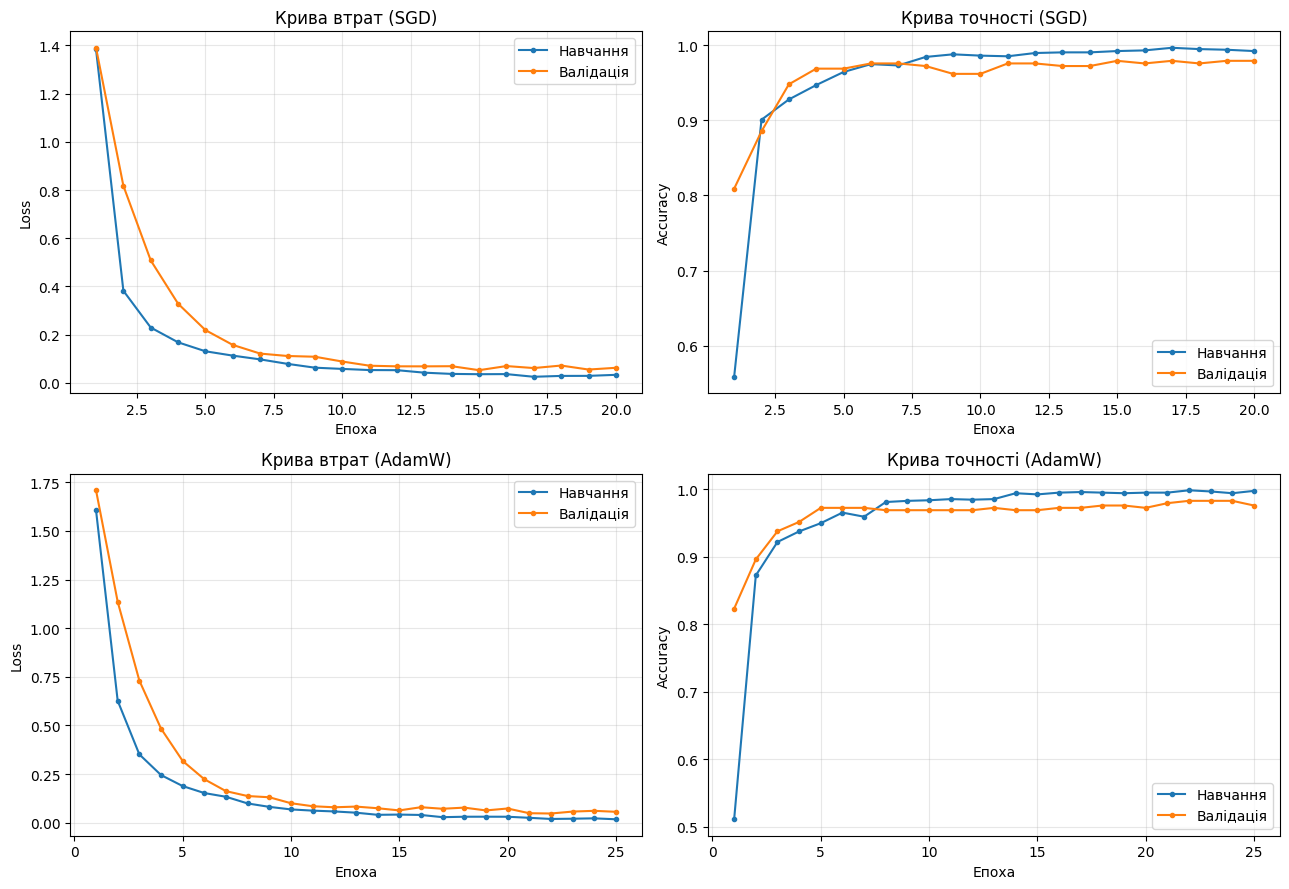

In [40]:
fig, axes = plt.subplots(2, 2, figsize = (13, 9))

histories = [
    ("SGD", student_history_sgd),
    ("AdamW", student_history_adamw)
]

for i, (name, hist) in enumerate(histories):
    epochs_done = np.arange(1, len(hist.history["loss"]) + 1)

    # Крива втрат
    axes[i, 0].plot(
        epochs_done, hist.history["loss"],
        label = "Навчання", marker = "o", ms = 3
    )
    axes[i, 0].plot(
        epochs_done, hist.history["val_loss"],
        label = "Валідація", marker = "o", ms = 3
    )
    axes[i, 0].set(
        title = f"Крива втрат ({name})",
        xlabel = "Епоха",
        ylabel = "Loss"
    )
    axes[i, 0].legend()
    axes[i, 0].grid(alpha = 0.3)

    # Крива точності
    axes[i, 1].plot(
        epochs_done, hist.history["accuracy"],
        label = "Навчання", marker = "o", ms = 3
    )
    axes[i, 1].plot(
        epochs_done, hist.history["val_accuracy"],
        label = "Валідація", marker = "o", ms = 3
    )
    axes[i, 1].set(
        title = f"Крива точності ({name})",
        xlabel = "Епоха",
        ylabel = "Accuracy"
    )
    axes[i, 1].legend()
    axes[i, 1].grid(alpha = 0.3)

plt.tight_layout()
plt.show()

###**Пояснення:**

Спочатку за допомогою `plt.subplots(2, 2, figsize=(13, 9))` створюється область із чотирма графіками, розташованими у два рядки та два стовпці, для порівняння процесу навчання нейронних мереж з оптимізаторами `SGD` та `AdamW`.

Далі у списку `histories` зберігаються назви оптимізаторів та відповідні історії навчання `student_history_sgd` і `student_history_adamw`. За допомогою циклу `for` послідовно обробляються результати обох моделей, а функція `np.arange()` формує масив номерів епох відповідно до фактичної тривалості навчання кожної з них.

Для кожного оптимізатора будуються два графіки:

- Крива втрат (`loss / val_loss`) – відображає зміну значень функції втрат на навчальній та валідаційній вибірках протягом кожної епохи.

- Крива точності (`accuracy / val_accuracy`) – демонструє динаміку точності класифікації на навчальних і валідаційних даних.

Для побудови кривих використовується метод `plot()`, а за допомогою `set()`, `legend()` та `grid()` задаються назви графіків, підписи осей, легенди та координатні сітки. Функція `plt.tight_layout()` забезпечує оптимальне розташування графіків, а `plt.show()` виводить їх на екран.

Аналіз кривих навчання з оптимізатором `SGD` показує, що на початкових епохах значення функції втрат стрімко зменшуються як на навчальній, так і на валідаційній вибірках. Зокрема, навчальні втрати знизилися з 1.3832 до 0.0335, а валідаційні – з 1.3899 до мінімального значення 0.0528 на 15-й епосі. Після цього валідаційні втрати почали незначно коливатися, тоді як навчальні продовжували зменшуватися. Це може свідчити про появу початкових ознак перенавчання.

Графік точності для `SGD` демонструє швидке зростання показників протягом перших епох. Навчальна точність збільшилася з 55,87% до 99,22% на останній епосі, а валідаційна – з 80,90% до 97,92%. Починаючи приблизно з 6–8-ї епохи, валідаційна точність стабілізується на рівні 96–98%, тоді як навчальна продовжує поступово зростати. Завдяки механізму `EarlyStopping` навчання було автоматично припинено після 20-ї епохи, а ваги моделі відновлено до стану 15-ї епохи.

Аналіз кривих навчання з оптимізатором `AdamW` також показує суттєве зменшення значень функції втрат протягом перших епох. Навчальні втрати знизилися з 1.6068 до 0.0175, а валідаційні – з 1.7093 до мінімального значення 0.0471 на 22-й епосі. Після початкового стрімкого зниження валідаційні втрати продовжували поступово зменшуватися з незначними коливаннями.

Графік точності для `AdamW` демонструє зростання навчальної точності з 51,09% до 99,74%, а валідаційної – з 82,29% до 97,57% на останній епосі. Водночас максимальна валідаційна точність становила 98,26%, що було досягнуто на 22–24-й епохах. Після приблизно 8–10-ї епохи валідаційна точність стабілізується на високому рівні, тоді як навчальна продовжує зростати. Це свідчить про наявність незначного розриву між навчальними та валідаційними показниками, проте суттєвого погіршення якості на валідаційній вибірці не спостерігається.

Порівняння отриманих графіків показує, що обидва оптимізатори забезпечують швидке зменшення функції втрат і досягнення високої точності класифікації. `SGD` досяг найменших валідаційних втрат на 15-й епосі та завершив навчання після 20 епох, тоді як `AdamW` продовжував покращувати валідаційні показники до 22-ї епохи та завершив усі 25 запланованих епох.

За результатами навчання `AdamW` продемонстрував дещо кращі валідаційні показники, досягнувши мінімальних втрат 0.0471 та максимальної точності 98,26%, порівняно з 0.0528 і 97,92% для `SGD`.

### Крок 4. Перевірте якість на тестовій вибірці

Виконайте `evaluate()` для **`student_model`**, отримайте класи з `predict()`, виведіть accuracy і матрицю помилок. Порівняйте тестову точність із **`test_accuracy`** базової моделі.

Порівняння тестової точності моделей:
Базова модель (Adam): 97.78%
Нова модель (SGD):    97.50%
Нова модель (AdamW):  98.61%

Порівняння тестових втрат:
Базова модель (Adam): 0.0679
Нова модель (SGD):    0.0586
Нова модель (AdamW):  0.0493

Звіт класифікації (SGD):
              precision    recall  f1-score   support

           0      1.000     0.972     0.986        36
           1      0.944     0.944     0.944        36
           2      1.000     1.000     1.000        35
           3      1.000     0.973     0.986        37
           4      0.973     1.000     0.986        36
           5      0.974     1.000     0.987        37
           6      1.000     0.972     0.986        36
           7      0.947     1.000     0.973        36
           8      0.914     0.914     0.914        35
           9      1.000     0.972     0.986        36

    accuracy                          0.975       360
   macro avg      0.975     0.975     0.975       360
weighted avg      0.975     0.

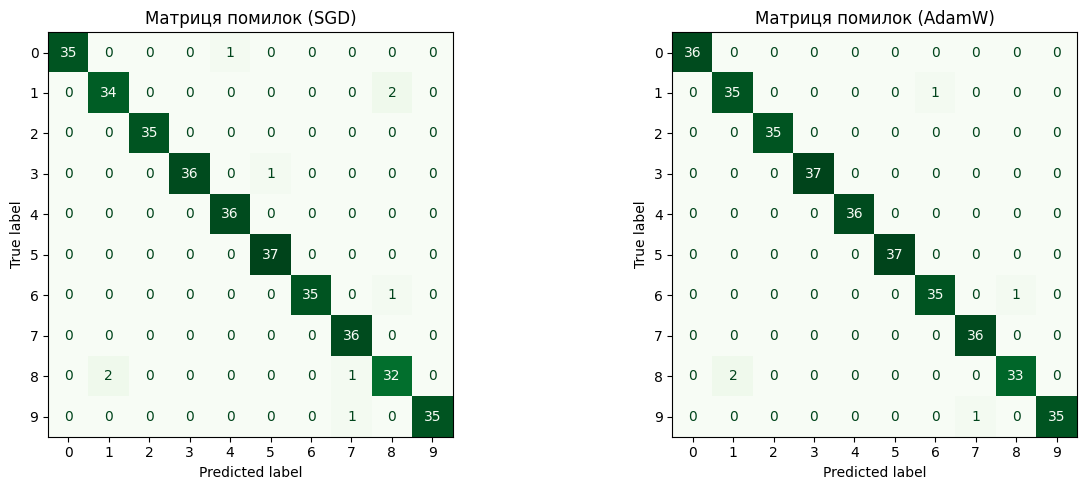

In [41]:
student_loss_sgd, student_accuracy_sgd = student_model_sgd.evaluate(
    x_test, y_test, verbose = 0
)

student_loss_adamw, student_accuracy_adamw = student_model_adamw.evaluate(
    x_test, y_test, verbose = 0
)

student_probabilities_sgd = student_model_sgd.predict(x_test, verbose = 0)
student_predictions_sgd = np.argmax(student_probabilities_sgd, axis = 1)

student_probabilities_adamw = student_model_adamw.predict(x_test, verbose = 0)
student_predictions_adamw = np.argmax(student_probabilities_adamw, axis = 1)

print("Порівняння тестової точності моделей:")
print(f"Базова модель (Adam): {test_accuracy:.2%}")
print(f"Нова модель (SGD):    {student_accuracy_sgd:.2%}")
print(f"Нова модель (AdamW):  {student_accuracy_adamw:.2%}")

print("\nПорівняння тестових втрат:")
print(f"Базова модель (Adam): {test_loss:.4f}")
print(f"Нова модель (SGD):    {student_loss_sgd:.4f}")
print(f"Нова модель (AdamW):  {student_loss_adamw:.4f}")

print("\nЗвіт класифікації (SGD):")
print(classification_report(
    y_test, student_predictions_sgd,
    digits = 3, zero_division = 0
))

print("\nЗвіт класифікації (AdamW):")
print(classification_report(
    y_test, student_predictions_adamw,
    digits = 3, zero_division = 0
))

fig, axes = plt.subplots(1, 2, figsize = (13, 5))

models_results = [
    ("SGD", student_predictions_sgd),
    ("AdamW", student_predictions_adamw)
]

for ax, (name, predictions) in zip(axes, models_results):
    matrix = confusion_matrix(
        y_test, predictions, labels = np.arange(10)
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix = matrix,
        display_labels = np.arange(10)
    )

    display_matrix.plot(
        ax = ax, cmap = "Greens",
        colorbar = False, values_format = "d"
    )

    ax.set_title(f"Матриця помилок ({name})")

plt.tight_layout()
plt.show()

###**Пояснення:**

Спочатку за допомогою методу `evaluate()` виконується оцінювання двох навчених нейронних мереж `student_model_sgd` та `student_model_adamw` на тестовій вибірці `x_test, y_test`, яка не використовувалася під час навчання та валідації. У результаті визначаються тестові втрати (`loss`) та точність класифікації (`accuracy`) для кожної моделі.

Далі за допомогою методу `predict()` формуються прогнози для всіх зображень тестової вибірки. Кожна модель повертає вектор із 10 імовірностей належності зображення до відповідних класів рукописних цифр. За допомогою функції `np.argmax(..., axis=1)` визначається прогнозований клас шляхом вибору індексу найбільшої імовірності.

Після цього за допомогою функції `print()` виводяться тестові втрати та точність трьох моделей: базової моделі з оптимізатором `Adam`, нової моделі з `SGD` та нової моделі з `AdamW`. Це дозволяє порівняти ефективність початкової та нової архітектур нейронної мережі.

За допомогою `classification_report()` формуються детальні звіти класифікації для моделей `SGD` та `AdamW`, які містять показники `precision`, `recall`, `f1-score` та `support` для кожного з десяти класів рукописних цифр.

Далі за допомогою `plt.subplots(1, 2, figsize=(13, 5))` створюється область із двома графіками для візуалізації матриць помилок. У циклі `for` за допомогою функції `confusion_matrix()` обчислюються матриці помилок для обох моделей, а `ConfusionMatrixDisplay()` забезпечує їх графічне представлення у вигляді теплових карт із колірною схемою `Greens`. Рядки матриць відповідають справжнім класам, а стовпці – прогнозованим. Значення на головній діагоналі показують кількість правильних прогнозів, а поза нею – помилкові класифікації.

Аналіз отриманих результатів показує, що найвищу тестову точність продемонструвала нова модель з оптимізатором `AdamW` – 98,61%. Вона правильно класифікувала 355 із 360 зображень, допустивши лише 5 помилок. Порівняно з базовою моделлю точність збільшилася на 0,83 відсоткового пункта, а кількість помилкових прогнозів зменшилася з 8 до 5.

Модель з оптимізатором `SGD` досягла тестової точності 97,50%, що на 0,28 відсотка нижче за результат базової моделі. Водночас її тестові втрати становили 0.0586, що менше за втрати базової моделі 0.0679. Це свідчить про те, що зменшення значення функції втрат не завжди супроводжується підвищенням частки правильних прогнозів.

Аналіз детальних метрик класифікації показує, що для моделі з оптимізатором `SGD` середні значення `precision`, `recall` та `f1-score` становлять 0.975. Найкращі результати отримано для класу 2, який був розпізнаний без помилок. Найнижче значення `F1-score` спостерігається для класу 8 – 0.914, що вказує на більшу складність розпізнавання цієї цифри.

Для моделі з оптимізатором `AdamW` середні значення `precision`, `recall` та `f1-score` становлять 0.986. Найкращі результати отримано для класів 0, 2, 3, 4 та 5, для яких усі три метрики дорівнюють 1.000. Найнижче значення `F1-score` спостерігається для класу 8 – 0.957, проте цей показник є вищим, ніж у моделі `SGD`.

Аналіз матриці помилок моделі `SGD` показує, що більшість зображень класифіковано правильно, однак допущено 9 помилок:

- Одне зображення цифри 0 класифіковано як 4.
- Два зображення цифри 1 класифіковано як 8.
- Одне зображення цифри 3 класифіковано як 5.
- Одне зображення цифри 6 класифіковано як 8.
- Два зображення цифри 8 класифіковано як 1, а одне – як 7.
- Одне зображення цифри 9 класифіковано як 7.

Аналіз матриці помилок моделі `AdamW` показує, що кількість неправильних прогнозів зменшилася до 5:

- Одне зображення цифри 1 класифіковано як 6.
- Одне зображення цифри 6 класифіковано як 8.
- Два зображення цифри 8 класифіковано як 1.
- Одне зображення цифри 9 класифіковано як 7.

Порівняння матриць помилок показує, що модель `AdamW` краще розпізнає більшість класів і допускає менше помилок, зокрема для цифр 0, 3 та 8. Водночас для обох моделей найбільш проблемним залишається розпізнавання цифри 8, яка в окремих випадках помилково класифікується як 1.

### Крок 5. Візуалізуйте щонайменше 12 прогнозів

Покажіть тестові зображення з підписами **«Справжній клас»** та **«Прогнозований клас»**. Правильні й помилкові результати виділіть різними кольорами. За наявності помилок додайте кілька помилкових прикладів.

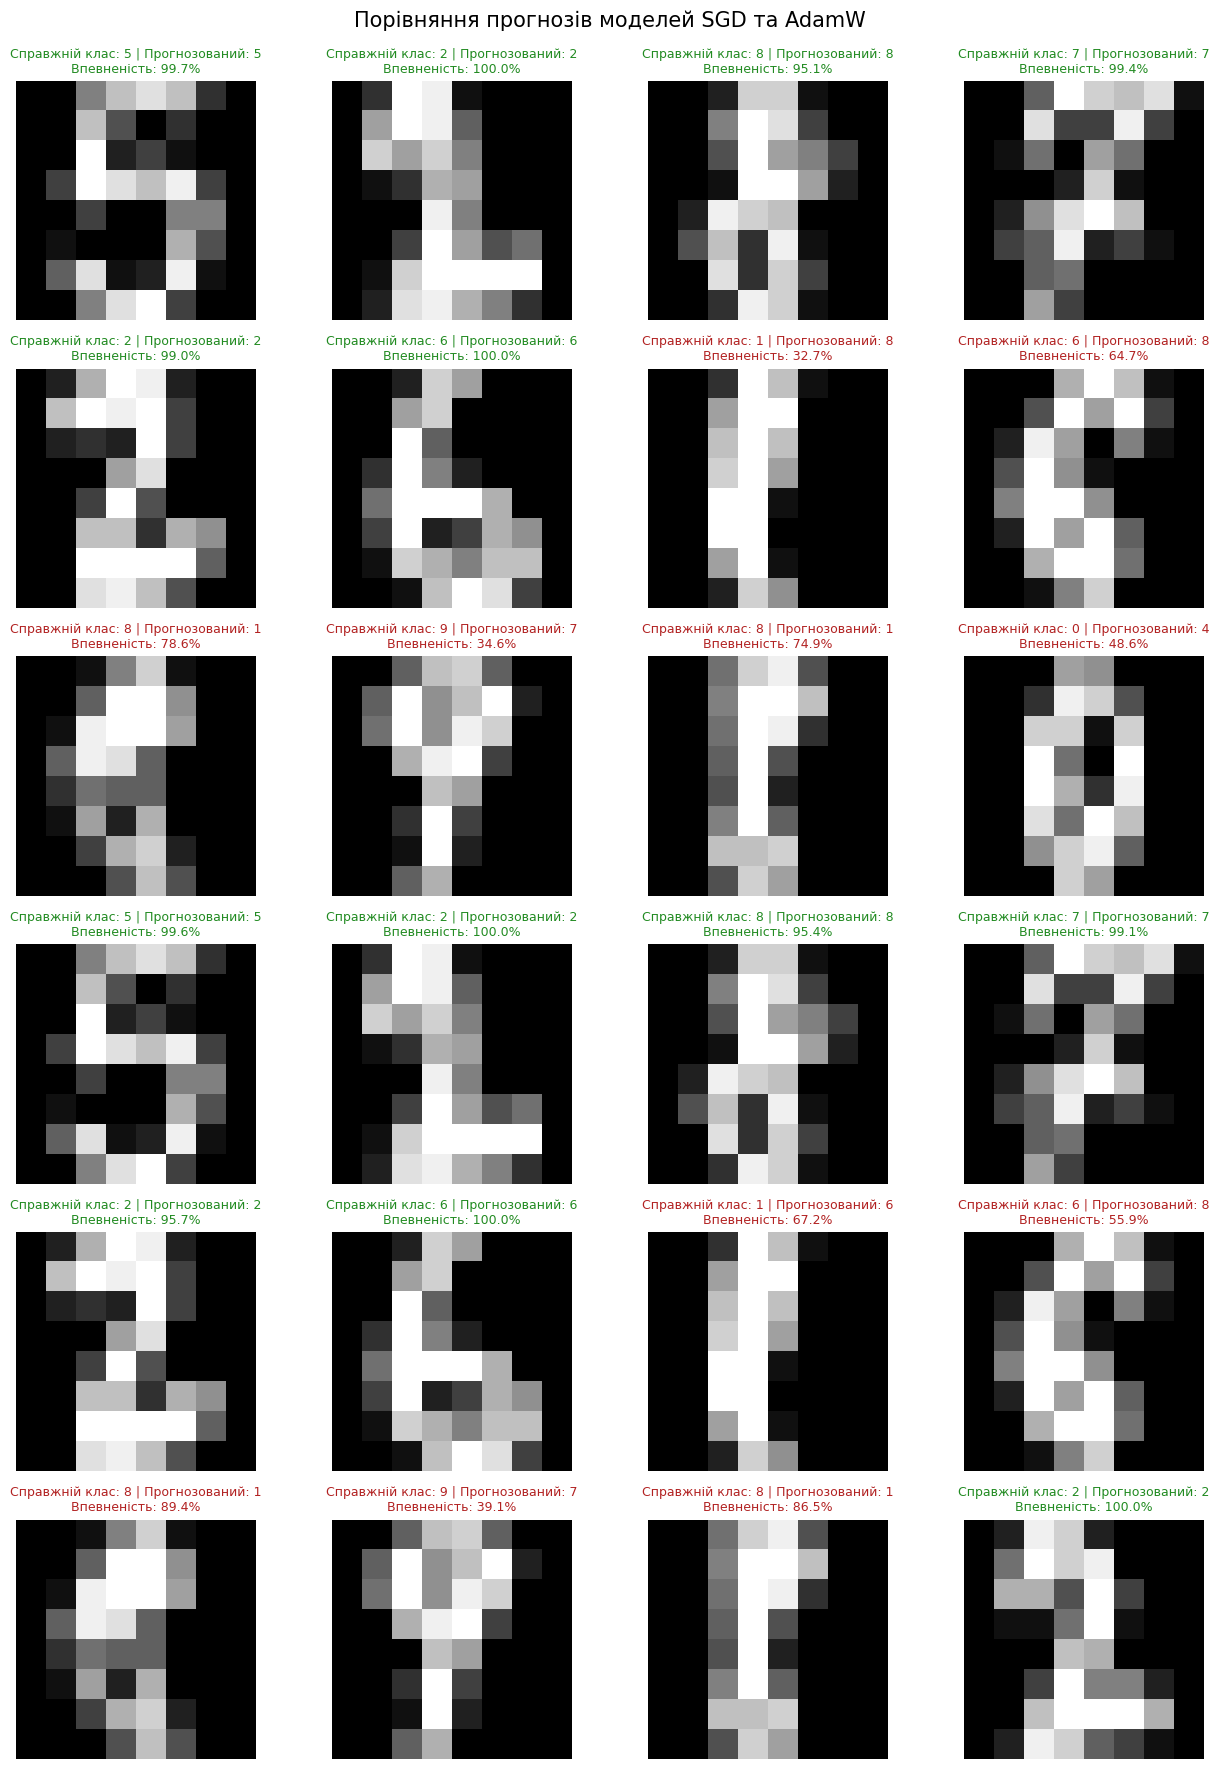

In [42]:
fig, axes = plt.subplots(6, 4, figsize = (13, 18))

models_predictions = [
    ("SGD", student_predictions_sgd, student_probabilities_sgd),
    ("AdamW", student_predictions_adamw, student_probabilities_adamw)
]

for model_idx, (name, predictions, probabilities) in enumerate(models_predictions):

    correct_idx = np.flatnonzero(predictions == y_test)
    wrong_idx = np.flatnonzero(predictions != y_test)

    selected = list(correct_idx[:6]) + list(wrong_idx[:6])

    if len(selected) < 12:
        selected += list(correct_idx[6:6 + (12 - len(selected))])

    confidence = probabilities.max(axis = 1)

    for j, idx in enumerate(selected):

        row = model_idx * 3 + j // 4
        col = j % 4
        ax = axes[row, col]

        is_correct = predictions[idx] == y_test[idx]
        color = "forestgreen" if is_correct else "firebrick"

        ax.imshow(x_test[idx], cmap = "gray", vmin = 0, vmax = 1)

        ax.set_title(
            f"Справжній клас: {y_test[idx]} | Прогнозований: {predictions[idx]}\n"
            f"Впевненість: {confidence[idx]:.1%}",
            color = color,
            fontsize = 9
        )

        ax.axis("off")

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_edgecolor(color)
            spine.set_linewidth(2)

fig.suptitle(
    "Порівняння прогнозів моделей SGD та AdamW\n",
    fontsize = 15
)

plt.tight_layout()
plt.show()

###**Пояснення:**

Спочатку за допомогою `plt.subplots(6, 4, figsize=(13, 18))` створюється область із 24 графіками, розташованими у шість рядків і чотири стовпці, для візуалізації результатів класифікації рукописних цифр двома нейронними мережами з оптимізаторами `SGD` та `AdamW`.

Далі у списку `models_predictions` зберігаються назви оптимізаторів, масиви прогнозованих класів `student_predictions_sgd` і `student_predictions_adamw`, а також відповідні масиви ймовірностей `student_probabilities_sgd` та `student_probabilities_adamw`.

За допомогою циклу `for` послідовно обробляються результати обох моделей. Функція `np.flatnonzero()` визначає індекси правильно та помилково класифікованих зображень шляхом порівняння прогнозованих класів зі справжніми мітками `y_test`.

Для кожної моделі формується список `selected`, до якого включаються перші шість правильних і до шести помилкових прогнозів. Якщо кількість помилкових прогнозів менша за шість, решта місць доповнюється правильно класифікованими зображеннями.

За допомогою `probabilities.max(axis=1)` визначається максимальна прогнозована ймовірність для кожного зображення, яка використовується як оцінка впевненості моделі у вибраному класі.

Далі за допомогою методу `imshow()` відображаються тестові зображення рукописних цифр у відтінках сірого. Для кожного зображення методом `set_title()` виводяться справжній клас, прогнозований клас та впевненість моделі у відсотках.

Для наочного розрізнення результатів використовуються два кольори:

- Зелений (`forestgreen`) – правильний прогноз, коли передбачений клас збігається зі справжнім.

- Червоний (`firebrick`) – помилковий прогноз, коли передбачений клас відрізняється від справжнього.

Координатні осі приховуються за допомогою `ax.axis("off")`, а рамки зображень налаштовуються відповідно до правильності класифікації. Перші три рядки графіків відображають результати моделі `SGD`, а наступні три – моделі `AdamW`.

Аналіз результатів моделі з оптимізатором `SGD` показує, що серед шести правильно класифікованих зображень представлені цифри 5, 2, 8, 7, 2 та 6. Впевненість моделі у правильних прогнозах становить від 95,1% до 100,0%, що свідчить про високу впевненість у розпізнаванні цих прикладів.

Найвища впевненість серед наведених помилкових прогнозів `SGD` спостерігається для цифри 8, яку модель помилково визначила як 1 з імовірністю 78,6%. Найнижча впевненість становить 32,7% для цифри 1, помилково класифікованої як 8.

Аналіз результатів моделі з оптимізатором `AdamW` показує, що серед правильно класифікованих зображень представлені цифри 5, 2, 8, 7, 2, 6 та 2. Впевненість моделі у правильних прогнозах становить від 95,4% до 100,0%.

Оскільки модель `AdamW` допустила лише п'ять помилок на всій тестовій вибірці, на графіках відображено всі п'ять помилкових прогнозів та сім правильних прикладів.

Найвища впевненість серед помилкових прогнозів `AdamW` спостерігається для цифри 8, яку модель визначила як 1 з імовірністю 89,4%. Це демонструє, що навіть висока впевненість моделі не завжди гарантує правильність класифікації.

Порівняння результатів обох моделей показує, що `SGD` та `AdamW` успішно розпізнають більшість наведених рукописних цифр, проте допускають окремі помилки через подібність графічних елементів різних цифр та низьку роздільну здатність зображень.

Для обох моделей характерні помилки під час розпізнавання цифри 8, яка в окремих випадках класифікується як 1. Також обидві моделі помилково визначають деякі зображення цифри 6 як 8 та цифри 9 як 7.

Водночас модель `AdamW` демонструє кращі загальні результати на тестовій вибірці, оскільки допустила 5 помилок порівняно з 9 помилками моделі `SGD`. Це узгоджується з отриманими раніше значеннями тестової точності: 98,61% для `AdamW` та 97,50% для `SGD`.

### Крок 6. Експериментуйте з одним параметром

Змініть **один** параметр нового варіанта (наприклад, `Dropout rate` або `learning_rate`), повторіть навчання та порівняйте результати. Поясніть, чому для коректного порівняння інші умови доцільно залишати сталими.

In [43]:
keras.utils.set_random_seed(42)

experiment_model = keras.Sequential([
    keras.Input(shape = (8, 8), name = "image"),
    layers.Flatten(name = "flatten"),
    layers.Dense(128, use_bias = False, name = "dense_128"),
    layers.BatchNormalization(name = "batch_norm"),
    layers.Activation("relu", name = "relu"),
    layers.Dropout(0.50, name = "dropout"),
    layers.Dense(64, activation = "relu", name = "dense_64"),
    layers.Dense(10, activation = "softmax", name = "classes"),
], name = "experiment_digits_mlp")

experiment_model.compile(
    optimizer = keras.optimizers.AdamW(
        learning_rate = 0.001,
        weight_decay = 0.0001
    ),
    loss = keras.losses.SparseCategoricalCrossentropy(),
    metrics = ["accuracy"]
)

experiment_early_stopping = keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience = 5,
    restore_best_weights = True
)

experiment_history = experiment_model.fit(
    x_train, y_train,
    validation_data = (x_val, y_val),
    epochs = 25,
    batch_size = 32,
    callbacks = [experiment_early_stopping],
    verbose = 1
)

print("\nПорівняння результатів:")

print("\nПочаткова модель AdamW (Dropout = 0.30):")
print("Кількість епох:", len(student_history_adamw.history["loss"]))
print("Найменші val_loss:",
      min(student_history_adamw.history["val_loss"]))
print("Найбільша val_accuracy:",
      max(student_history_adamw.history["val_accuracy"]))

print("\nЕкспериментальна модель AdamW (Dropout = 0.50):")
print("Кількість епох:", len(experiment_history.history["loss"]))
print("Найменші val_loss:",
      min(experiment_history.history["val_loss"]))
print("Найбільша val_accuracy:",
      max(experiment_history.history["val_accuracy"]))

Epoch 1/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3873 - loss: 1.8131 - val_accuracy: 0.8229 - val_loss: 1.8068
Epoch 2/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7633 - loss: 0.8909 - val_accuracy: 0.9097 - val_loss: 1.2751
Epoch 3/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8642 - loss: 0.5382 - val_accuracy: 0.9410 - val_loss: 0.8500
Epoch 4/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8816 - loss: 0.3968 - val_accuracy: 0.9479 - val_loss: 0.5625
Epoch 5/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9104 - loss: 0.3385 - val_accuracy: 0.9618 - val_loss: 0.3665
Epoch 6/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9269 - loss: 0.2662 - val_accuracy: 0.9722 - val_loss: 0.2565
Epoch 7/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9225 - loss: 0.2516 - val_accuracy: 0.9722 - val_loss: 0.1849
Epoch 8/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9530 - loss: 0.1843 - val_accuracy: 0.9722 - val_loss:

###**Пояснення:**

Спочатку за допомогою `keras.utils.set_random_seed(42)` встановлюється фіксоване початкове значення генераторів випадкових чисел для підвищення відтворюваності результатів експерименту.

Далі за допомогою `keras.Sequential()` створюється нова експериментальна модель повнозв’язної нейронної мережі `experiment_digits_mlp`, яка повторює архітектуру попередньої моделі з оптимізатором `AdamW`, але має змінене значення параметра регуляризації `Dropout`.

У початковій моделі використовувалося значення `Dropout(0.30)`, яке передбачає випадкове занулення 30% активацій під час навчання. В експериментальній моделі це значення збільшено до `Dropout(0.50)`, тобто до 50%. Така зміна дозволяє дослідити вплив сильнішої регуляризації на процес навчання та здатність нейронної мережі узагальнювати дані.

При цьому решта параметрів залишається незмінною: два приховані повнозв’язні шари зі 128 і 64 нейронами, функція активації `ReLU`, шар `BatchNormalization` та вихідний шар із 10 нейронами з функцією `softmax`.

Після створення моделі за допомогою методу `compile()` виконується її компіляція. Для навчання використовується оптимізатор `AdamW` зі швидкістю навчання `learning_rate=0.001` та коефіцієнтом регуляризації `weight_decay=0.0001`. Функція втрат `SparseCategoricalCrossentropy` використовується для багатокласової класифікації, а метрика `accuracy` – для оцінювання частки правильних прогнозів.

Далі налаштовується механізм `EarlyStopping`, який контролює значення `val_loss` та припиняє навчання після п’яти епох без покращення валідаційних втрат. Параметр `restore_best_weights=True` забезпечує відновлення ваг моделі, які відповідали найменшому значенню `val_loss`.

Навчання експериментальної моделі виконується за допомогою методу `fit()` на тих самих навчальній та валідаційній вибірках, що використовувалися для початкової моделі. Максимальна кількість епох становить 25, а розмір пакета `batch_size=32`. Історія навчання зберігається у змінній `experiment_history`.

Наприкінці за допомогою функції `print()` виводяться фактична кількість епох, найменше значення валідаційних втрат `val_loss` та найбільше значення валідаційної точності `val_accuracy` для початкової й експериментальної моделей.

Аналіз результатів навчання експериментальної моделі з `Dropout = 0.50` показує, що протягом перших епох відбулося поступове зменшення функції втрат та підвищення точності класифікації. На першій епосі навчальна точність становила 38,73%, а валідаційна – 82,29%. Наприкінці навчання ці показники зросли до 98,61% та 97,92% відповідно.

Навчальні втрати зменшилися з 1.8131 до 0.0514, а валідаційні – з 1.8068 до мінімального значення 0.0588, досягнутого на 20-й епосі. Після цього значення валідаційних втрат почали незначно коливатися, не демонструючи подальшого покращення. Максимальна валідаційна точність становила 98,26% на 24-й епосі.

Порівняння з початковою моделлю `AdamW` із `Dropout = 0.30` показує, що збільшення частки занулення активацій до 50% не забезпечило підвищення максимальної валідаційної точності. Для обох моделей цей показник залишився на рівні 98,26%.

Водночас найменше значення валідаційних втрат збільшилося з 0.0471 до 0.0588, тобто приблизно на 0,0117. Це свідчить про дещо гірший результат експериментальної моделі за функцією втрат, незважаючи на однакову максимальну точність класифікації.

Також спостерігається повільніше зростання навчальної точності при використанні `Dropout = 0.50`, що можна пояснити сильнішою регуляризацією. Оскільки під час навчання випадково занулюється більша частина активацій, нейронній мережі складніше пристосовуватися до навчальних прикладів, що може уповільнювати процес засвоєння закономірностей.

Для забезпечення коректності експерименту було змінено лише один параметр – значення `Dropout` із 0.30 до 0.50. Архітектура повнозв’язних шарів, оптимізатор `AdamW`, швидкість навчання, функція втрат, розмір пакета, максимальна кількість епох та навчальна й валідаційна вибірки залишилися незмінними. Це дозволяє порівнювати результати та пов’язувати виявлені відмінності насамперед зі зміною інтенсивності регуляризації, хоча для надійнішого підтвердження впливу параметра доцільно провести кілька повторних запусків.

### Висновок студента

Додайте в наступну порожню комірку Markdown короткий висновок (5–8 речень): яка з моделей показала кращу тестову якість, що демонструють криві навчання, які класи було складніше розпізнавати та як вплинула змінена гіперпараметрична настройка.

###**Підсумкові висновки:**

За результатами проведених експериментів найкращу тестову якість продемонструвала нова повнозв’язна нейронна мережа з оптимізатором `AdamW`, яка досягла точності 98,61%, правильно класифікувавши 355 із 360 тестових зображень.

Для порівняння, базова модель з оптимізатором `Adam` досягла точності 97,78%, а нова модель з `SGD` – 97,50%.

Аналіз кривих навчання показав поступове зменшення функції втрат і зростання точності для обох нових моделей, що свідчить про успішне засвоєння закономірностей даних, хоча на пізніх епохах спостерігалися незначні ознаки перенавчання.

Використання механізму `EarlyStopping` дозволило контролювати валідаційні втрати та відновлювати найкращі ваги моделей. Аналіз матриць помилок і візуалізації прогнозів показав, що найскладнішою для розпізнавання була цифра 8, яку моделі в окремих випадках помилково класифікували як 1.

Додатковий експеримент зі збільшенням параметра `Dropout` із 0.30 до 0.50 показав, що максимальна валідаційна точність залишилася незмінною на рівні 98,26%, проте мінімальні валідаційні втрати збільшилися з 0,0471 до 0,0588.

Це свідчить про те, що посилення регуляризації не завжди покращує якість нейронної мережі, а її параметри необхідно підбирати експериментально.

Таким чином, найефективнішим серед досліджених варіантів виявилася модель з оптимізатором `AdamW` та `Dropout = 0.30`, яка забезпечила найвищу тестову точність і найменші тестові втрати серед трьох основних моделей.